# Brazilian E-commerce Sales and Fulfillment Analysis, 2017-2018: Growth, Seasonality, Delivery vs. Estimates

### Analysis scope, definitions and guardrails

| Item | Definition used in this notebook |
| --- | --- |
| **Analysis window** | Orders purchased **2017-01-01 to 2018-08-31**. 2016 (329 orders, partial coverage with gaps) and Sep-Oct 2018 (incomplete) are excluded from every analysis except the data-coverage checks in Section 1. |
| **Orders placed** | Every order in the window, any status (demand view). |
| **Valid orders** | Orders in the window that are not `canceled` or `unavailable`. Used for all value and freight metrics. |
| **Delivered orders** | `order_status = 'delivered'`, with a delivery date, an estimate, and delivery on/after purchase. Used for all delivery metrics. |
| **Order value (GMV)** | Sum of item `price` per order. **Freight** is summed `freight_value` per order. Both are aggregated to the order level before averaging. |
| **Delivery gap** | `estimated delivery date - actual delivery date` in calendar days. Positive = early, negative = late. |
| **On-time rate** | Share of delivered orders with gap >= 0. |
| **Delivery time** | Purchase to customer delivery in fractional days (24-hour periods). |
| **State rankings** | Only states with at least `MIN_ORDERS_PER_STATE` orders are ranked, to avoid conclusions from tiny samples. |
| **Skewed metrics** | Mean and median are reported together. |

**Not measurable with this dataset (no data):** net profit margin, CAC, cart abandonment, revenue per visitor, inventory turnover, true return/refund rate, true LTV. `freight_value` is the shipping charge on an item, **not** a cost to Target, so no margin conclusions are drawn from it.

### 1. Initial Exploration & Data Characteristics

* **Q1.1:** What are the data types of all columns in the 8 tables?
* **Q1.2:** What is the overall time range during which orders were placed, and which periods are excluded?
* **Q1.3:** What is the total count of distinct cities and states where ordering customers are located?
* **Q1.4 (guardrail):** What is the order status mix and are there date inconsistencies?

### 2. In-Depth Exploration & Order Trends

* **Q2.1:** Is there a growing trend in the number of orders placed over time?
* **Q2.2:** How do order volumes vary across months of the year, split by year (seasonality)?
* **Q2.3:** How do order volumes vary across hours and time windows of the day?
* **Q2.4:** How do order volumes vary across days of the week?

### 3. Evolution of E-Commerce in Brazil

* **Q3.1:** What is the Month-on-Month (MoM) order count across customer states?
* **Q3.2:** How are orders and unique customers distributed across states?

### 4. Impact on Economy: Price & Freight Analysis

* **Q4.1:** What is the percentage change in order value (GMV) and freight between 2017 and 2018?
* **Q4.2:** What are the total and average order prices per customer state?
* **Q4.3:** What are the total and average freight costs per order per customer state, and is freight lower where order value is higher?

### 5. Delivery Performance & Freight Analysis

* **Q5.1:** What is the delivery time distribution, the delivery gap, the on-time rate and its effect on review scores?
* **Q5.2:** Which are the 5 states with the highest and lowest average freight per order?
* **Q5.3:** Which are the 5 states with the slowest and fastest average delivery times?
* **Q5.4:** Which 5 states deliver earliest relative to the estimate, and which have the lowest on-time rate?
* **Q5.5 (supplementary):** Is the freight/delivery advantage explained by seller location or by volume?

### 6. Payment Analysis

* **Q6.1:** What is the Month-on-Month order count for each payment type?
* **Q6.2:** What is the total number of orders per year for each payment type?
* **Q6.3:** How are orders distributed by number of payment installments?

### 7. Key Metrics Summary

## Setup

In [1]:
%pip install --quiet duckdb pandas matplotlib seaborn ipython

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import duckdb
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
import pandas as pd
import seaborn as sns
from IPython.display import display

# ==============================================================================
# CONFIGURATION
# ==============================================================================
DATA_DIR = "assets/dataset"  # Path to your CSV folder
OUTPUT_DIR = "assets/charts"  # Path to save generated charts and tables

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Analysis window: 2016 is partial, Sep-Oct 2018 is incomplete
ANALYSIS_START = "2017-01-01"
ANALYSIS_END_EXCLUSIVE = "2018-09-01"
MIN_ORDERS_PER_STATE = 100  # Minimum orders for a state to be ranked

# Set global Seaborn & Matplotlib styles
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 10, "figure.autolayout": True})

# Brazilian state code -> state name (IBGE / ISO 3166-2:BR, 26 states + Federal District)
STATE_NAMES = {
    "AC": "Acre", "AL": "Alagoas", "AP": "Amapá", "AM": "Amazonas",
    "BA": "Bahia", "CE": "Ceará", "DF": "Distrito Federal", "ES": "Espírito Santo",
    "GO": "Goiás", "MA": "Maranhão", "MT": "Mato Grosso", "MS": "Mato Grosso do Sul",
    "MG": "Minas Gerais", "PA": "Pará", "PB": "Paraíba", "PR": "Paraná",
    "PE": "Pernambuco", "PI": "Piauí", "RJ": "Rio de Janeiro", "RN": "Rio Grande do Norte",
    "RS": "Rio Grande do Sul", "RO": "Rondônia", "RR": "Roraima", "SC": "Santa Catarina",
    "SP": "São Paulo", "SE": "Sergipe", "TO": "Tocantins",
}
PAYMENT_LABELS = {
    "credit_card": "Credit Card",
    "UPI": "UPI",
    "voucher": "Voucher",
    "debit_card": "Debit Card",
}
MONTH_LABELS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def pretty(text):
    """Readable label: no underscores, proper case."""
    return PAYMENT_LABELS.get(str(text), str(text).replace("_", " ").title())


def label_axes(ax, title, xlabel, ylabel):
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)


def print_insights(lines):
    print("Insights:")
    for line in lines:
        print(f"  - {line}")


# ==============================================================================
# DUCKDB IN-MEMORY SETUP & PRE-TYPING (LOAD ONCE)
# ==============================================================================
con = duckdb.connect(database=":memory:")

csv_tables = [
    "customers",
    "sellers",
    "geolocation",
    "payments",
    "order_items",
    "order_reviews",
    "products",
]

# Load standard tables via Pandas to handle Latin1 encoding flawlessly
for table in csv_tables:
    file_path = os.path.join(DATA_DIR, f"{table}.csv")
    df_temp = pd.read_csv(file_path, encoding="latin1", low_memory=False)
    con.execute(f"CREATE TABLE {table} AS SELECT * FROM df_temp")

# Load orders table via Pandas and pre-cast timestamps in DuckDB RAM
orders_path = os.path.join(DATA_DIR, "orders.csv")
df_orders = pd.read_csv(orders_path, encoding="latin1", low_memory=False)

con.execute(
    """
    CREATE TABLE orders AS 
    SELECT 
        order_id, 
        customer_id, 
        order_status,
        TRY_CAST(order_purchase_timestamp AS TIMESTAMP) AS order_purchase_timestamp,
        TRY_CAST(order_approved_at AS TIMESTAMP) AS order_approved_at,
        TRY_CAST(order_delivered_carrier_date AS TIMESTAMP) AS order_delivered_carrier_date,
        TRY_CAST(order_delivered_customer_date AS TIMESTAMP) AS order_delivered_customer_date,
        TRY_CAST(order_estimated_delivery_date AS TIMESTAMP) AS order_estimated_delivery_date
    FROM df_orders;
"""
)

# State code -> state name lookup
df_states = pd.DataFrame(list(STATE_NAMES.items()), columns=["state_code", "state_name"])
con.execute("CREATE TABLE state_names AS SELECT * FROM df_states")

# ------------------------------------------------------------------------------
# ANALYSIS VIEWS (window + edge-case filters applied once, reused everywhere)
# ------------------------------------------------------------------------------
# Orders placed: every order in the analysis window, any status
con.execute(
    f"""
    CREATE VIEW orders_window AS
    SELECT * FROM orders
    WHERE order_purchase_timestamp >= TIMESTAMP '{ANALYSIS_START}'
      AND order_purchase_timestamp <  TIMESTAMP '{ANALYSIS_END_EXCLUSIVE}';
"""
)

# Valid orders: excludes canceled / unavailable (used for value & freight)
con.execute(
    """
    CREATE VIEW valid_orders AS
    SELECT * FROM orders_window
    WHERE order_status NOT IN ('canceled', 'unavailable');
"""
)

# Order-level price and freight (aggregated BEFORE averaging)
con.execute(
    """
    CREATE VIEW order_values AS
    SELECT
        o.order_id,
        c.customer_state,
        EXTRACT(YEAR FROM o.order_purchase_timestamp) AS order_year,
        EXTRACT(MONTH FROM o.order_purchase_timestamp) AS order_month,
        SUM(oi.price) AS order_price,
        SUM(oi.freight_value) AS order_freight
    FROM valid_orders o
    JOIN customers c ON o.customer_id = c.customer_id
    JOIN order_items oi ON o.order_id = oi.order_id
    GROUP BY ALL;
"""
)

# Delivery metrics: delivered orders only, with consistent dates
con.execute(
    """
    CREATE VIEW delivery_metrics AS
    SELECT
        o.order_id,
        c.customer_state,
        DATE_DIFF('second', o.order_purchase_timestamp, o.order_delivered_customer_date) / 86400.0 AS time_to_deliver_days,
        DATE_DIFF('day', CAST(o.order_purchase_timestamp AS DATE), CAST(o.order_estimated_delivery_date AS DATE)) AS promised_days,
        DATE_DIFF('day', CAST(o.order_delivered_customer_date AS DATE), CAST(o.order_estimated_delivery_date AS DATE)) AS diff_estimated_delivery
    FROM orders_window o
    JOIN customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
      AND o.order_delivered_customer_date >= o.order_purchase_timestamp;
"""
)

print(
    f"✓ All 8 CSV tables successfully loaded into DuckDB memory from '{DATA_DIR}'."
)
print(
    f"✓ Analysis window: {ANALYSIS_START} to 2018-08-31 | min orders per ranked state: {MIN_ORDERS_PER_STATE}\n"
)


# ==============================================================================
# FAST DATAFRAME TO IMAGE EXPORTER
# ==============================================================================
def save_df_as_image(df: pd.DataFrame, filepath: str, max_rows: int = 10):
    """Renders top dataframe rows as an image without memory leaks."""
    sub_df = df.head(max_rows).astype(str)

    fig, ax = plt.subplots(
        figsize=(
            max(6, len(sub_df.columns) * 1.8),
            max(1.8, len(sub_df) * 0.35 + 0.6),
        )
    )
    ax.axis("off")

    tbl = ax.table(
        cellText=sub_df.values,
        colLabels=sub_df.columns,
        loc="center",
        cellLoc="center",
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    tbl.scale(1.1, 1.2)

    plt.savefig(filepath, dpi=200, bbox_inches="tight")
    plt.close(fig)  # Prevents Matplotlib memory leaks
    plt.close("all")

✓ All 8 CSV tables successfully loaded into DuckDB memory from 'assets/dataset'.
✓ Analysis window: 2017-01-01 to 2018-08-31 | min orders per ranked state: 100



## **Q1.1:** What are the data types of all columns in the 8 tables?

In [3]:
QUERY_Q1_1 = """
    SELECT table_name, column_name, data_type
    FROM information_schema.columns
    WHERE table_schema = 'main'
      AND table_name IN ('customers', 'geolocation', 'order_items', 'payments',
                         'order_reviews', 'orders', 'products', 'sellers')
    ORDER BY table_name, ordinal_position;
"""

df_1_1 = con.execute(QUERY_Q1_1).df()
display(df_1_1)
save_df_as_image(df_1_1, f"{OUTPUT_DIR}/table_1_1.jpg", max_rows=len(df_1_1))

text_dates = df_1_1[
    df_1_1["column_name"].str.contains("date|timestamp", regex=True)
    & (df_1_1["data_type"] == "VARCHAR")
]
print_insights(
    [
        f"{df_1_1['table_name'].nunique()} tables and {len(df_1_1)} columns profiled.",
        f"{len(text_dates)} date/time columns outside `orders` are stored as text (VARCHAR) and must be cast before any date arithmetic: "
        + ", ".join(text_dates["column_name"].tolist()),
        "`orders` timestamps were cast to TIMESTAMP at load time (TRY_CAST turns unparseable values into NULL).",
    ]
)

,table_name,column_name,data_type
0,customers,customer_id,VARCHAR
1,customers,customer_unique_id,VARCHAR
2,customers,customer_zip_code_prefix,BIGINT
3,customers,customer_city,VARCHAR
4,customers,customer_state,VARCHAR
5,geolocation,geolocation_zip_code_prefix,BIGINT
6,geolocation,geolocation_lat,DOUBLE
7,geolocation,geolocation_lng,DOUBLE
8,geolocation,geolocation_city,VARCHAR
9,geolocation,geolocation_state,VARCHAR


Insights:
  - 8 tables and 49 columns profiled.
  - 3 date/time columns outside `orders` are stored as text (VARCHAR) and must be cast before any date arithmetic: shipping_limit_date, review_creation_date, review_answer_timestamp
  - `orders` timestamps were cast to TIMESTAMP at load time (TRY_CAST turns unparseable values into NULL).


## **Q1.2:** What is the overall time range during which orders were placed, and which periods are excluded?

In [4]:
QUERY_Q1_2 = """
    SELECT 
        MIN(order_purchase_timestamp) AS min_date,
        MAX(order_purchase_timestamp) AS max_date,
        COUNT(*) AS total_orders
    FROM orders
    WHERE order_purchase_timestamp IS NOT NULL;
"""

QUERY_Q1_2_EXCLUDED = f"""
    SELECT
        STRFTIME(order_purchase_timestamp, '%Y-%m') AS year_month,
        COUNT(*) AS order_count
    FROM orders
    WHERE order_purchase_timestamp < TIMESTAMP '{ANALYSIS_START}'
       OR order_purchase_timestamp >= TIMESTAMP '{ANALYSIS_END_EXCLUSIVE}'
    GROUP BY year_month
    ORDER BY year_month ASC;
"""

df_1_2 = con.execute(QUERY_Q1_2).df()
display(df_1_2)
save_df_as_image(df_1_2, f"{OUTPUT_DIR}/table_1_2.jpg")

df_1_2b = con.execute(QUERY_Q1_2_EXCLUDED).df()
display(df_1_2b)
save_df_as_image(df_1_2b, f"{OUTPUT_DIR}/table_1_2b.jpg", max_rows=len(df_1_2b))

total_orders = int(df_1_2["total_orders"].iloc[0])
excluded = int(df_1_2b["order_count"].sum())
print_insights(
    [
        f"Orders span {str(df_1_2['min_date'].iloc[0])[:10]} to {str(df_1_2['max_date'].iloc[0])[:10]} ({total_orders:,} orders).",
        f"Analysis window is Jan 2017 to Aug 2018. {excluded:,} orders ({excluded / total_orders * 100:.2f}%) fall outside it and are excluded.",
        "Excluded months (partial or incomplete coverage): " + ", ".join(df_1_2b["year_month"]),
        "Only two calendar years remain, so a yearly trend cannot be established; trend is assessed on monthly data and Jan-Aug vs Jan-Aug.",
    ]
)

,min_date,max_date,total_orders
0,2016-09-04 21:15:19,2018-10-17 17:30:18,99441


,year_month,order_count
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2018-09,16
4,2018-10,4


Insights:
  - Orders span 2016-09-04 to 2018-10-17 (99,441 orders).
  - Analysis window is Jan 2017 to Aug 2018. 349 orders (0.35%) fall outside it and are excluded.
  - Excluded months (partial or incomplete coverage): 2016-09, 2016-10, 2016-12, 2018-09, 2018-10
  - Only two calendar years remain, so a yearly trend cannot be established; trend is assessed on monthly data and Jan-Aug vs Jan-Aug.


## **Q1.3:** What is the total count of distinct cities and states where ordering customers are located?

In [5]:
QUERY_Q1_3 = """
    SELECT
        COUNT(DISTINCT (c.customer_state, LOWER(TRIM(c.customer_city)))) AS city_count,
        COUNT(DISTINCT c.customer_state) AS state_count
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id;
"""

df_1_3 = con.execute(QUERY_Q1_3).df()
display(df_1_3)
save_df_as_image(df_1_3, f"{OUTPUT_DIR}/table_1_3.jpg")

print_insights(
    [
        f"Orders come from {int(df_1_3['state_count'].iloc[0])} states (27 expected incl. the Federal District) and {int(df_1_3['city_count'].iloc[0]):,} distinct cities.",
        "Cities are counted as unique (state, lower-cased trimmed name) pairs, so identical names in different states are kept apart.",
    ]
)

,city_count,state_count
0,4310,27


Insights:
  - Orders come from 27 states (27 expected incl. the Federal District) and 4,310 distinct cities.
  - Cities are counted as unique (state, lower-cased trimmed name) pairs, so identical names in different states are kept apart.


## **Q1.4 (guardrail):** What is the order status mix and are there date inconsistencies?

In [6]:
QUERY_Q1_4 = """
    SELECT
        order_status,
        COUNT(*) AS order_count,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_orders
    FROM orders_window
    GROUP BY order_status
    ORDER BY order_count DESC;
"""

QUERY_Q1_4_QUALITY = """
    SELECT
        COUNT(*) FILTER (WHERE order_status = 'delivered' AND order_delivered_customer_date IS NULL) AS delivered_without_delivery_date,
        COUNT(*) FILTER (WHERE order_delivered_customer_date < order_purchase_timestamp) AS delivery_before_purchase,
        COUNT(*) FILTER (WHERE order_status <> 'delivered' AND order_delivered_customer_date IS NOT NULL) AS non_delivered_with_delivery_date
    FROM orders_window;
"""

df_1_4 = con.execute(QUERY_Q1_4).df()
display(df_1_4)
save_df_as_image(df_1_4, f"{OUTPUT_DIR}/table_1_4.jpg", max_rows=len(df_1_4))

df_1_4b = con.execute(QUERY_Q1_4_QUALITY).df()
display(df_1_4b)
save_df_as_image(df_1_4b, f"{OUTPUT_DIR}/table_1_4b.jpg")

status = df_1_4.set_index("order_status")["pct_of_orders"]
non_ful = status.reindex(["canceled", "unavailable"]).fillna(0).sum()
print_insights(
    [
        f"Delivered orders are {status.get('delivered', 0):.2f}% of orders placed in the window.",
        f"Canceled + unavailable orders are {non_ful:.2f}%; they are excluded from value/freight metrics and all delivery metrics.",
        "Other non-delivered statuses (shipped, processing, invoiced, approved, created) are excluded from delivery metrics because they have no final delivery date.",
        f"Date checks: {int(df_1_4b['delivered_without_delivery_date'].iloc[0])} delivered orders lack a delivery date, "
        f"{int(df_1_4b['delivery_before_purchase'].iloc[0])} show delivery before purchase (removed from delivery metrics).",
    ]
)

,order_status,order_count,pct_of_orders
0,delivered,96211,97.09
1,shipped,1097,1.11
2,unavailable,602,0.61
3,canceled,580,0.59
4,processing,299,0.30
5,invoiced,296,0.30
6,created,5,0.01
7,approved,2,0.00


,delivered_without_delivery_date,delivery_before_purchase,non_delivered_with_delivery_date
0,8,0,1


Insights:
  - Delivered orders are 97.09% of orders placed in the window.
  - Canceled + unavailable orders are 1.20%; they are excluded from value/freight metrics and all delivery metrics.
  - Other non-delivered statuses (shipped, processing, invoiced, approved, created) are excluded from delivery metrics because they have no final delivery date.
  - Date checks: 8 delivered orders lack a delivery date, 0 show delivery before purchase (removed from delivery metrics).


## **Q2.1:** Is there a growing trend in the number of orders placed over time?

,year_month,total_orders,mom_pct_change
0,2017-01,800,NaN
1,2017-02,1780,122.50
2,2017-03,2682,50.67
3,2017-04,2404,-10.37
4,2017-05,3700,53.91
5,2017-06,3245,-12.30
6,2017-07,4026,24.07
7,2017-08,4331,7.58
8,2017-09,4285,-1.06
9,2017-10,4631,8.07


,year,jan_aug_orders
0,2017,22968
1,2018,53991


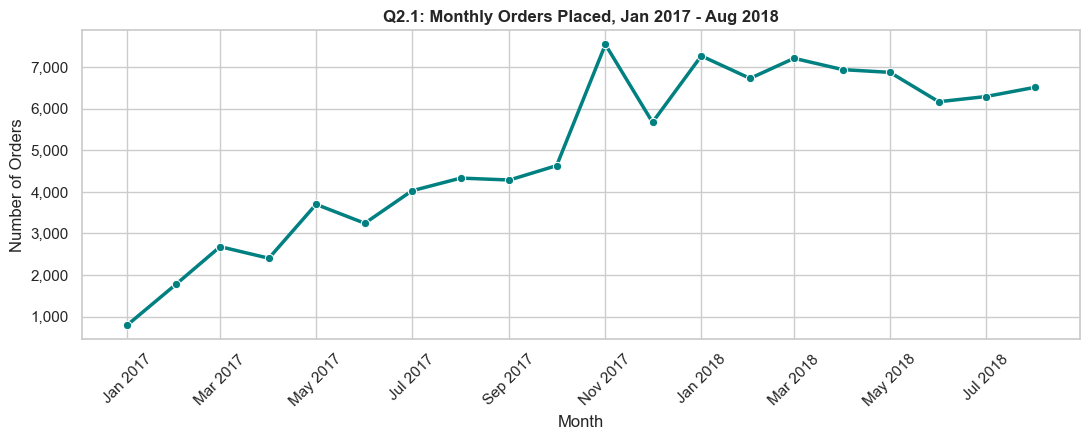

Insights:
  - Like-for-like (Jan-Aug) orders: 22,968 in 2017 vs 53,991 in 2018 (+135.1%).
  - Peak month: 2017-11 with 7,544 orders.
  - Average MoM change: 15.8% (median 3.5%).
  - A calendar-year comparison (12 months vs 8 months) would understate growth, so it is not used.


In [7]:
QUERY_Q2_1 = """
    WITH monthly AS (
        SELECT
            STRFTIME(order_purchase_timestamp, '%Y-%m') AS year_month,
            COUNT(order_id) AS total_orders
        FROM orders_window
        GROUP BY year_month
    )
    SELECT
        year_month,
        total_orders,
        ROUND(100.0 * (total_orders - LAG(total_orders) OVER (ORDER BY year_month))
              / NULLIF(LAG(total_orders) OVER (ORDER BY year_month), 0), 2) AS mom_pct_change
    FROM monthly
    ORDER BY year_month ASC;
"""

QUERY_Q2_1_YOY = """
    SELECT
        EXTRACT(YEAR FROM order_purchase_timestamp) AS year,
        COUNT(order_id) AS jan_aug_orders
    FROM orders_window
    WHERE EXTRACT(MONTH FROM order_purchase_timestamp) BETWEEN 1 AND 8
    GROUP BY year
    ORDER BY year ASC;
"""

df_2_1 = con.execute(QUERY_Q2_1).df()
display(df_2_1.head(10))
save_df_as_image(df_2_1, f"{OUTPUT_DIR}/table_2_1.jpg", max_rows=len(df_2_1))

df_2_1b = con.execute(QUERY_Q2_1_YOY).df()
display(df_2_1b)
save_df_as_image(df_2_1b, f"{OUTPUT_DIR}/table_2_1b.jpg")

plot_df = df_2_1.assign(month_start=pd.to_datetime(df_2_1["year_month"] + "-01"))
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.lineplot(data=plot_df, x="month_start", y="total_orders", marker="o", linewidth=2.5, color="teal", ax=ax)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
label_axes(ax, "Q2.1: Monthly Orders Placed, Jan 2017 - Aug 2018", "Month", "Number of Orders")
plt.savefig(f"{OUTPUT_DIR}/chart_2_1.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

yoy = df_2_1b.set_index("year")["jan_aug_orders"]
peak = df_2_1.loc[df_2_1["total_orders"].idxmax()]
print_insights(
    [
        f"Like-for-like (Jan-Aug) orders: {int(yoy[2017]):,} in 2017 vs {int(yoy[2018]):,} in 2018 ({(yoy[2018] / yoy[2017] - 1) * 100:+.1f}%).",
        f"Peak month: {peak['year_month']} with {int(peak['total_orders']):,} orders.",
        f"Average MoM change: {df_2_1['mom_pct_change'].mean():.1f}% (median {df_2_1['mom_pct_change'].median():.1f}%).",
        "A calendar-year comparison (12 months vs 8 months) would understate growth, so it is not used.",
    ]
)

**Limitation:** with only two years of usable data, a yearly trend cannot be established. Evidence of growth rests on the 20-month series and the Jan-Aug comparison.

## **Q2.2:** How do order volumes vary across months of the year, split by year (seasonality)?

,year,month,total_orders
0,2017,1,800
1,2017,2,1780
2,2017,3,2682
3,2017,4,2404
4,2017,5,3700
5,2017,6,3245
6,2017,7,4026
7,2017,8,4331
8,2017,9,4285
9,2017,10,4631


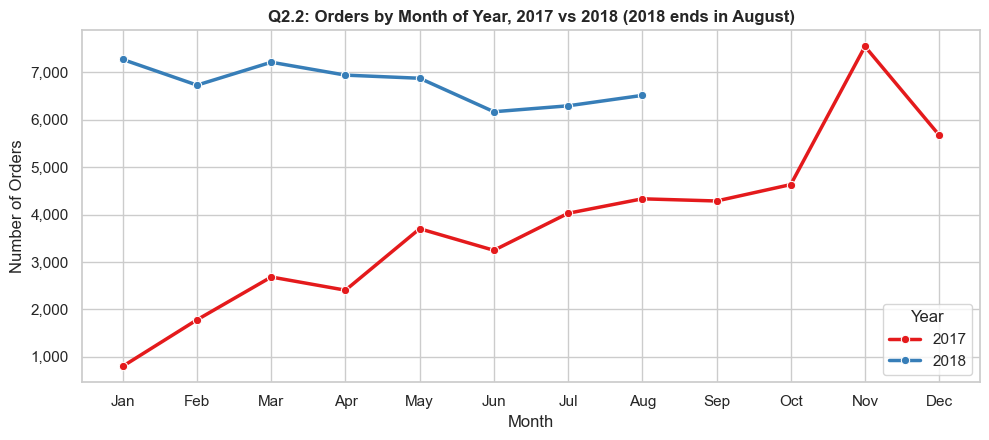

Insights:
  - Peak month by year: 2017: Nov, 2018: Jan.
  - Average orders per month in Jan-Aug: 2017: 2,871, 2018: 6,749.
  - Sep-Dec exist for 2017 only, so seasonality for those months cannot be compared across years.
  - Nov 2017 vs Oct 2017: +62.9% (a sharp jump, consistent with Black Friday).


In [8]:
QUERY_Q2_2 = """
    SELECT
        EXTRACT(YEAR FROM order_purchase_timestamp) AS year,
        EXTRACT(MONTH FROM order_purchase_timestamp) AS month,
        COUNT(order_id) AS total_orders
    FROM orders_window
    GROUP BY year, month
    ORDER BY year ASC, month ASC;
"""

df_2_2 = con.execute(QUERY_Q2_2).df()
display(df_2_2.head(10))
save_df_as_image(df_2_2, f"{OUTPUT_DIR}/table_2_2.jpg", max_rows=len(df_2_2))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(data=df_2_2, x="month", y="total_orders", hue="year", marker="o", linewidth=2.5, palette="Set1", ax=ax)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTH_LABELS)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(title="Year")
label_axes(ax, "Q2.2: Orders by Month of Year, 2017 vs 2018 (2018 ends in August)", "Month", "Number of Orders")
plt.savefig(f"{OUTPUT_DIR}/chart_2_2.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

pivot = df_2_2.pivot(index="month", columns="year", values="total_orders")
peaks = {int(y): MONTH_LABELS[int(pivot[y].idxmax()) - 1] for y in pivot.columns}
jan_aug = pivot.loc[1:8].mean()
lines = [
    "Peak month by year: " + ", ".join(f"{y}: {m}" for y, m in peaks.items()) + ".",
    "Average orders per month in Jan-Aug: " + ", ".join(f"{int(y)}: {v:,.0f}" for y, v in jan_aug.items()) + ".",
    "Sep-Dec exist for 2017 only, so seasonality for those months cannot be compared across years.",
]
if 2017 in pivot.columns and pd.notna(pivot.loc[10, 2017]) and pd.notna(pivot.loc[11, 2017]):
    nov_jump = (pivot.loc[11, 2017] / pivot.loc[10, 2017] - 1) * 100
    lines.append(f"Nov 2017 vs Oct 2017: {nov_jump:+.1f}%" + (" (a sharp jump, consistent with Black Friday)." if nov_jump > 20 else " (no sharp November spike)."))
print_insights(lines)

## **Q2.3:** How do order volumes vary across hours and time windows of the day?

,purchase_hour,time_of_day,order_count
0,0,Dawn,2387
1,1,Dawn,1168
2,2,Dawn,506
3,3,Dawn,272
4,4,Dawn,203
5,5,Dawn,188
6,6,Dawn,502
7,7,Morning,1225
8,8,Morning,2953
9,9,Morning,4765


,time_of_day,order_count,pct_of_orders
0,Afternoon,38005,38.35
1,Night,28240,28.50
2,Morning,27621,27.87
3,Dawn,5226,5.27


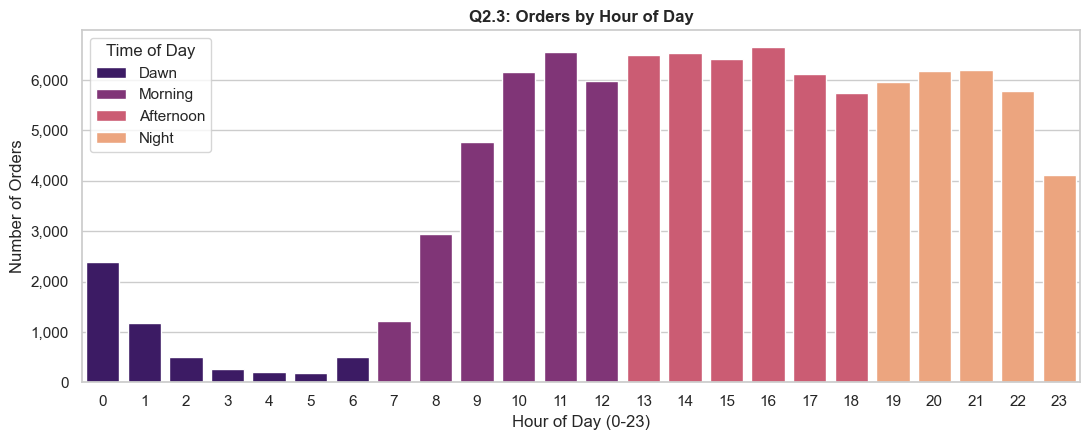

Insights:
  - Busiest time window: Afternoon (38.4% of orders); quietest: Dawn (5.3%).
  - Peak hour: 16:00 with 6,655 orders.
  - Windows: Dawn 00-06, Morning 07-12, Afternoon 13-18, Night 19-23.


In [9]:
QUERY_Q2_3 = """
    WITH hourly AS (
        SELECT
            EXTRACT(HOUR FROM order_purchase_timestamp) AS purchase_hour,
            COUNT(*) AS order_count
        FROM orders_window
        GROUP BY purchase_hour
    )
    SELECT
        purchase_hour,
        CASE
            WHEN purchase_hour BETWEEN 0 AND 6 THEN 'Dawn'
            WHEN purchase_hour BETWEEN 7 AND 12 THEN 'Morning'
            WHEN purchase_hour BETWEEN 13 AND 18 THEN 'Afternoon'
            ELSE 'Night'
        END AS time_of_day,
        order_count
    FROM hourly
    ORDER BY purchase_hour ASC;
"""

QUERY_Q2_3_BUCKET = """
    WITH tagged AS (
        SELECT
            CASE
                WHEN EXTRACT(HOUR FROM order_purchase_timestamp) BETWEEN 0 AND 6 THEN 'Dawn'
                WHEN EXTRACT(HOUR FROM order_purchase_timestamp) BETWEEN 7 AND 12 THEN 'Morning'
                WHEN EXTRACT(HOUR FROM order_purchase_timestamp) BETWEEN 13 AND 18 THEN 'Afternoon'
                ELSE 'Night'
            END AS time_of_day
        FROM orders_window
    )
    SELECT
        time_of_day,
        COUNT(*) AS order_count,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_orders
    FROM tagged
    GROUP BY time_of_day
    ORDER BY order_count DESC;
"""

df_2_3 = con.execute(QUERY_Q2_3).df()
display(df_2_3.head(10))
save_df_as_image(df_2_3, f"{OUTPUT_DIR}/table_2_3.jpg", max_rows=len(df_2_3))

df_2_3b = con.execute(QUERY_Q2_3_BUCKET).df()
display(df_2_3b)
save_df_as_image(df_2_3b, f"{OUTPUT_DIR}/table_2_3b.jpg")

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(
    data=df_2_3, x="purchase_hour", y="order_count", hue="time_of_day",
    hue_order=["Dawn", "Morning", "Afternoon", "Night"], dodge=False, palette="magma", ax=ax,
)
ax.legend(title="Time of Day")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
label_axes(ax, "Q2.3: Orders by Hour of Day", "Hour of Day (0-23)", "Number of Orders")
plt.savefig(f"{OUTPUT_DIR}/chart_2_3.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

top_hour = df_2_3.loc[df_2_3["order_count"].idxmax()]
print_insights(
    [
        f"Busiest time window: {df_2_3b['time_of_day'].iloc[0]} ({df_2_3b['pct_of_orders'].iloc[0]:.1f}% of orders); quietest: {df_2_3b['time_of_day'].iloc[-1]} ({df_2_3b['pct_of_orders'].iloc[-1]:.1f}%).",
        f"Peak hour: {int(top_hour['purchase_hour']):02d}:00 with {int(top_hour['order_count']):,} orders.",
        "Windows: Dawn 00-06, Morning 07-12, Afternoon 13-18, Night 19-23.",
    ]
)

## **Q2.4:** How do order volumes vary across days of the week?

,day_number,day_of_week,order_count,pct_of_orders
0,1,Monday,16141,16.29
1,2,Tuesday,15896,16.04
2,3,Wednesday,15501,15.64
3,4,Thursday,14704,14.84
4,5,Friday,14075,14.20
5,6,Saturday,10843,10.94
6,7,Sunday,11932,12.04


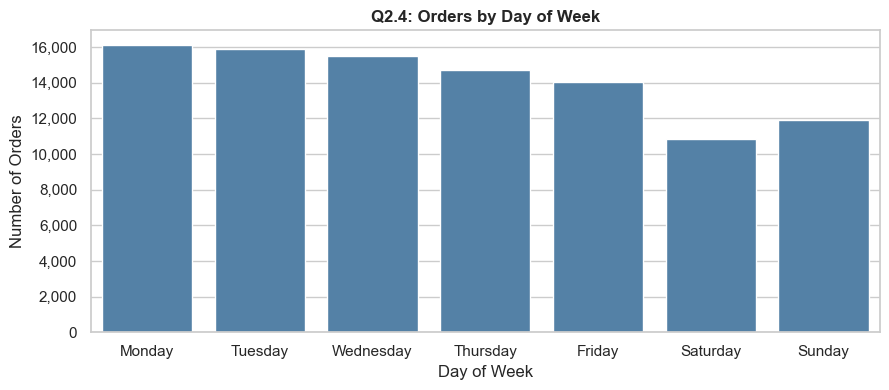

Insights:
  - Busiest day: Monday (16.3% of orders); quietest: Saturday (10.9%).
  - Weekend (Sat+Sun) share: 23.0% of orders vs 28.6% if volume were evenly spread.


In [10]:
QUERY_Q2_4 = """
    SELECT
        ISODOW(order_purchase_timestamp) AS day_number,
        DAYNAME(order_purchase_timestamp) AS day_of_week,
        COUNT(*) AS order_count,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_orders
    FROM orders_window
    GROUP BY day_number, day_of_week
    ORDER BY day_number ASC;
"""

df_2_4 = con.execute(QUERY_Q2_4).df()
display(df_2_4)
save_df_as_image(df_2_4, f"{OUTPUT_DIR}/table_2_4.jpg")

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=df_2_4, x="day_of_week", y="order_count", color="steelblue", ax=ax)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
label_axes(ax, "Q2.4: Orders by Day of Week", "Day of Week", "Number of Orders")
plt.savefig(f"{OUTPUT_DIR}/chart_2_4.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

hi, lo = df_2_4.loc[df_2_4["order_count"].idxmax()], df_2_4.loc[df_2_4["order_count"].idxmin()]
wk = df_2_4[df_2_4["day_number"] >= 6]["pct_of_orders"].sum()
print_insights(
    [
        f"Busiest day: {hi['day_of_week']} ({hi['pct_of_orders']:.1f}% of orders); quietest: {lo['day_of_week']} ({lo['pct_of_orders']:.1f}%).",
        f"Weekend (Sat+Sun) share: {wk:.1f}% of orders vs 28.6% if volume were evenly spread.",
    ]
)

## **Q3.1:** What is the Month-on-Month (MoM) order count across customer states?

,customer_state,state_name,year_month,order_count
0,AC,Acre,2017-01,2
1,AL,Alagoas,2017-01,2
2,BA,Bahia,2017-01,25
3,CE,Ceará,2017-01,9
4,DF,Distrito Federal,2017-01,13
5,ES,Espírito Santo,2017-01,12
6,GO,Goiás,2017-01,18
7,MA,Maranhão,2017-01,9
8,MG,Minas Gerais,2017-01,108
9,MS,Mato Grosso do Sul,2017-01,1


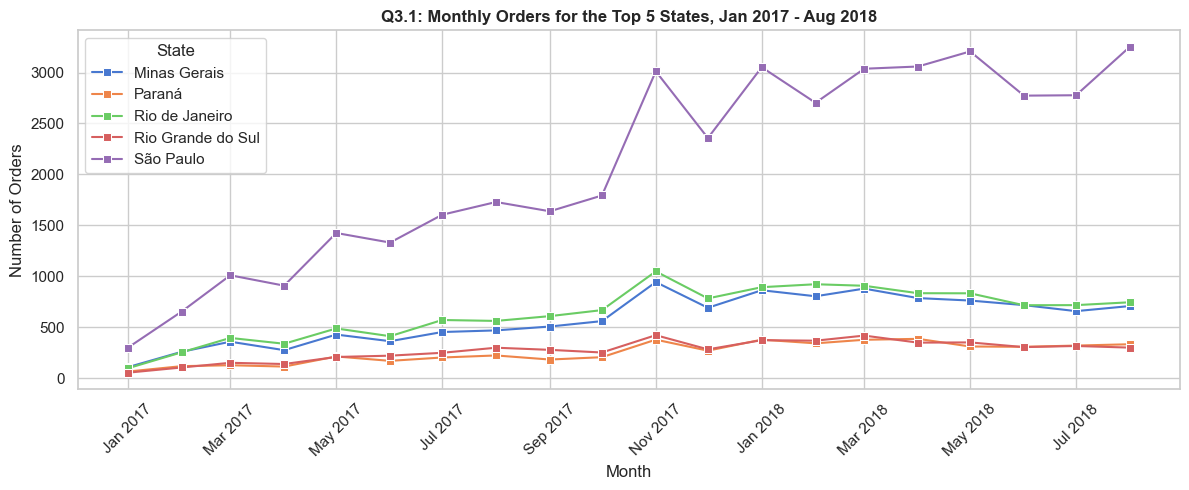

Insights:
  - Top 5 states (São Paulo, Rio de Janeiro, Minas Gerais, Rio Grande do Sul, Paraná) account for 77.2% of orders in the window.
  - 3 of 27 states recorded at least one month with zero orders out of 20, so small-state monthly series are noisy.


In [11]:
QUERY_Q3_1 = """
    SELECT 
        c.customer_state,
        sn.state_name,
        STRFTIME(o.order_purchase_timestamp, '%Y-%m') AS year_month,
        COUNT(o.order_id) AS order_count
    FROM customers c
    JOIN orders_window o ON c.customer_id = o.customer_id
    JOIN state_names sn ON c.customer_state = sn.state_code
    GROUP BY c.customer_state, sn.state_name, year_month
    ORDER BY year_month ASC, c.customer_state ASC;
"""

df_3_1 = con.execute(QUERY_Q3_1).df()
display(df_3_1.head(10))
save_df_as_image(df_3_1, f"{OUTPUT_DIR}/table_3_1.jpg")

top_5_states = df_3_1.groupby("state_name")["order_count"].sum().nlargest(5).index
df_3_1_filtered = df_3_1[df_3_1["state_name"].isin(top_5_states)].assign(
    month_start=lambda d: pd.to_datetime(d["year_month"] + "-01")
)
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=df_3_1_filtered, x="month_start", y="order_count", hue="state_name", marker="s", ax=ax)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
ax.legend(title="State")
label_axes(ax, "Q3.1: Monthly Orders for the Top 5 States, Jan 2017 - Aug 2018", "Month", "Number of Orders")
plt.savefig(f"{OUTPUT_DIR}/chart_3_1.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

state_pivot = df_3_1.pivot_table(index="year_month", columns="customer_state", values="order_count", fill_value=0)
all_months = state_pivot.shape[0]
sparse = int((state_pivot == 0).any().sum())
top5_share = df_3_1[df_3_1["state_name"].isin(top_5_states)]["order_count"].sum() / df_3_1["order_count"].sum() * 100
print_insights(
    [
        f"Top 5 states ({', '.join(top_5_states)}) account for {top5_share:.1f}% of orders in the window.",
        f"{sparse} of {state_pivot.shape[1]} states recorded at least one month with zero orders out of {all_months}, so small-state monthly series are noisy.",
    ]
)

## **Q3.2:** How are orders and unique customers distributed across states?

,customer_state,state_name,total_orders,total_customers,pct_of_orders
0,SP,São Paulo,41621,40186,42.00
1,RJ,Rio de Janeiro,12792,12330,12.91
2,MG,Minas Gerais,11591,11222,11.70
3,RS,Rio Grande do Sul,5441,5252,5.49
4,PR,Paraná,5025,4863,5.07
5,SC,Santa Catarina,3625,3523,3.66
6,BA,Bahia,3376,3273,3.41
7,DF,Distrito Federal,2134,2069,2.15
8,ES,Espírito Santo,2029,1960,2.05
9,GO,Goiás,2011,1944,2.03


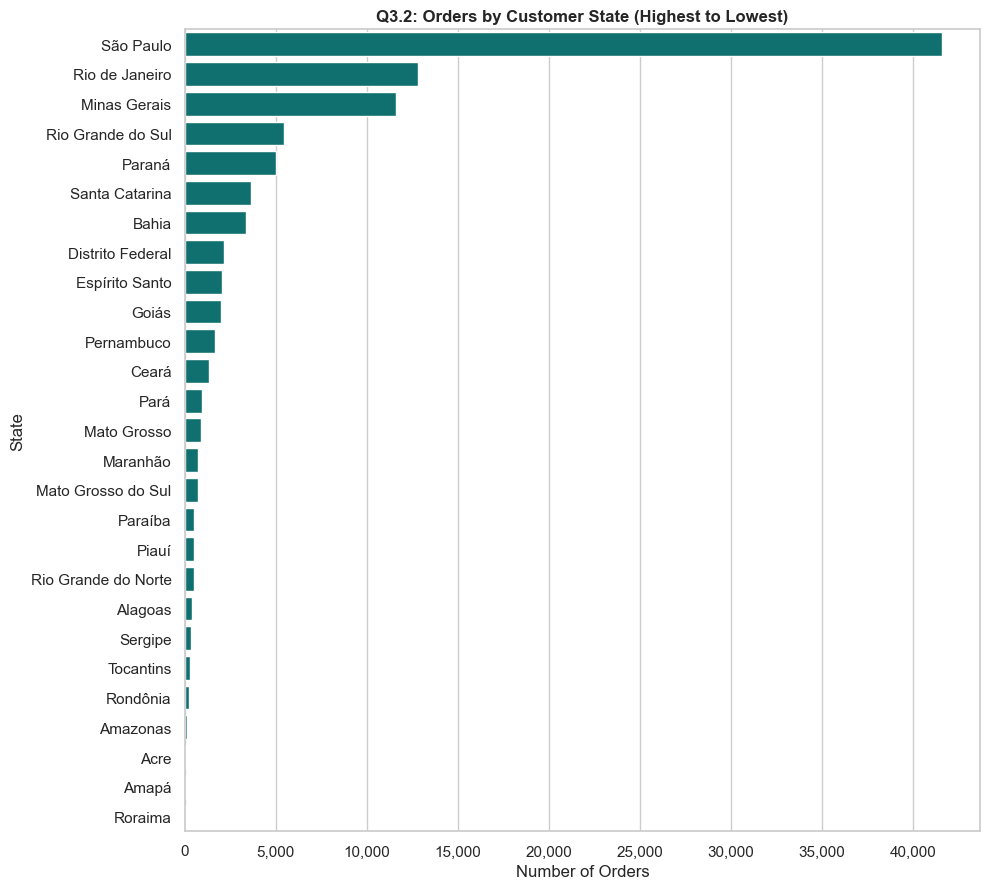

Insights:
  - Top 3 states: São Paulo (42.0%), Rio de Janeiro (12.9%), Minas Gerais (11.7%) = 66.6% of orders.
  - 15 of 27 states each contribute under 1% of orders.


In [12]:
QUERY_Q3_2 = """
    SELECT 
        c.customer_state,
        sn.state_name,
        COUNT(o.order_id) AS total_orders,
        COUNT(DISTINCT c.customer_unique_id) AS total_customers,
        ROUND(100.0 * COUNT(o.order_id) / SUM(COUNT(o.order_id)) OVER (), 2) AS pct_of_orders
    FROM customers c
    JOIN orders_window o ON c.customer_id = o.customer_id
    JOIN state_names sn ON c.customer_state = sn.state_code
    GROUP BY c.customer_state, sn.state_name
    ORDER BY total_orders DESC;
"""

df_3_2 = con.execute(QUERY_Q3_2).df()
display(df_3_2.head(10))
save_df_as_image(df_3_2, f"{OUTPUT_DIR}/table_3_2.jpg", max_rows=len(df_3_2))

fig, ax = plt.subplots(figsize=(10, 9))
sns.barplot(data=df_3_2, y="state_name", x="total_orders", color="teal", ax=ax)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
label_axes(ax, "Q3.2: Orders by Customer State (Highest to Lowest)", "Number of Orders", "State")
plt.savefig(f"{OUTPUT_DIR}/chart_3_2.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

top3 = df_3_2.head(3)
small = int((df_3_2["pct_of_orders"] < 1).sum())
print_insights(
    [
        f"Top 3 states: " + ", ".join(f"{r.state_name} ({r.pct_of_orders:.1f}%)" for r in top3.itertuples()) + f" = {top3['pct_of_orders'].sum():.1f}% of orders.",
        f"{small} of {len(df_3_2)} states each contribute under 1% of orders.",
    ]
)

## **Q4.1:** What is the percentage change in order value (GMV) and freight between 2017 and 2018?

,period,gmv_2017,gmv_2018,gmv_pct_change,freight_2017,freight_2018,freight_pct_change
0,Aug,568245.79,848860.10,49.38,93657.73,148113.41,58.14
1,Jan-Aug,3080850.81,7341037.41,138.28,494141.23,1252100.09,153.39


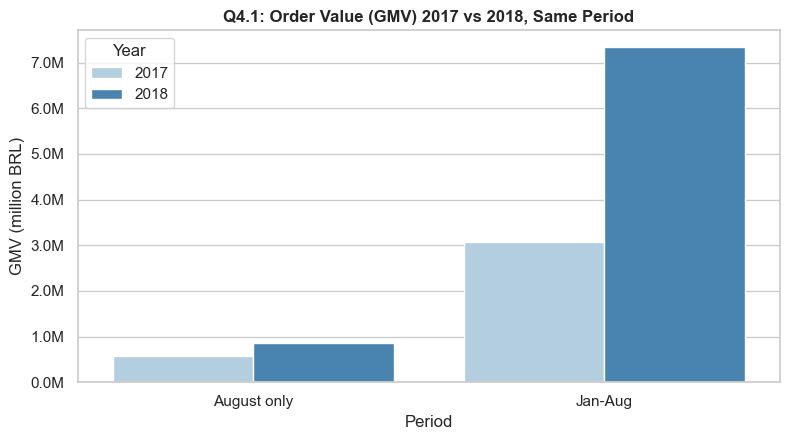

Insights:
  - Jan-Aug GMV rose +138.3% (BRL 3,080,851 to BRL 7,341,037); freight charged rose +153.4%.
  - August 2017 vs August 2018: GMV +49.4%, freight +58.1%.
  - Values are nominal BRL (not inflation-adjusted) and cover valid orders only (canceled/unavailable excluded).


In [13]:
QUERY_Q4_1 = """
    WITH periods AS (
        SELECT 'Jan-Aug' AS period, order_year, order_price, order_freight FROM order_values WHERE order_month BETWEEN 1 AND 8
        UNION ALL
        SELECT 'Aug' AS period, order_year, order_price, order_freight FROM order_values WHERE order_month = 8
    )
    SELECT
        period,
        ROUND(SUM(order_price) FILTER (WHERE order_year = 2017), 2) AS gmv_2017,
        ROUND(SUM(order_price) FILTER (WHERE order_year = 2018), 2) AS gmv_2018,
        ROUND(100.0 * (SUM(order_price) FILTER (WHERE order_year = 2018) - SUM(order_price) FILTER (WHERE order_year = 2017))
              / NULLIF(SUM(order_price) FILTER (WHERE order_year = 2017), 0), 2) AS gmv_pct_change,
        ROUND(SUM(order_freight) FILTER (WHERE order_year = 2017), 2) AS freight_2017,
        ROUND(SUM(order_freight) FILTER (WHERE order_year = 2018), 2) AS freight_2018,
        ROUND(100.0 * (SUM(order_freight) FILTER (WHERE order_year = 2018) - SUM(order_freight) FILTER (WHERE order_year = 2017))
              / NULLIF(SUM(order_freight) FILTER (WHERE order_year = 2017), 0), 2) AS freight_pct_change
    FROM periods
    GROUP BY period
    ORDER BY period ASC;
"""

df_4_1 = con.execute(QUERY_Q4_1).df()
display(df_4_1)
save_df_as_image(df_4_1, f"{OUTPUT_DIR}/table_4_1.jpg")

p_df = df_4_1.melt(id_vars="period", value_vars=["gmv_2017", "gmv_2018"], var_name="Year", value_name="GMV (BRL)")
p_df["Year"] = p_df["Year"].str[-4:]
p_df["period"] = p_df["period"].map({"Jan-Aug": "Jan-Aug", "Aug": "August only"})
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=p_df, x="period", y="GMV (BRL)", hue="Year", palette="Blues", ax=ax)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1e6:.1f}M"))
label_axes(ax, "Q4.1: Order Value (GMV) 2017 vs 2018, Same Period", "Period", "GMV (million BRL)")
plt.savefig(f"{OUTPUT_DIR}/chart_4_1.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

ja = df_4_1.set_index("period").loc["Jan-Aug"]
au = df_4_1.set_index("period").loc["Aug"]
print_insights(
    [
        f"Jan-Aug GMV rose {ja['gmv_pct_change']:+.1f}% (BRL {ja['gmv_2017']:,.0f} to BRL {ja['gmv_2018']:,.0f}); freight charged rose {ja['freight_pct_change']:+.1f}%.",
        f"August 2017 vs August 2018: GMV {au['gmv_pct_change']:+.1f}%, freight {au['freight_pct_change']:+.1f}%.",
        "Values are nominal BRL (not inflation-adjusted) and cover valid orders only (canceled/unavailable excluded).",
    ]
)

## **Q4.2:** What are the total and average order prices per customer state?

,customer_state,state_name,order_count,total_order_price,avg_order_price,median_order_price
0,SP,São Paulo,41021,5150778.70,125.56,79.80
1,RJ,Rio de Janeiro,12654,1802436.24,142.44,89.99
2,MG,Minas Gerais,11457,1568855.98,136.93,89.90
3,RS,Rio Grande do Sul,5395,739357.46,137.04,89.00
4,PR,Paraná,4962,674867.55,136.01,84.99
5,SC,Santa Catarina,3590,516340.22,143.83,89.90
6,BA,Bahia,3340,506214.78,151.56,94.00
7,DF,Distrito Federal,2114,299842.68,141.84,87.74
8,GO,Goiás,1990,286886.07,144.16,90.00
9,ES,Espírito Santo,2014,272614.34,135.36,89.00


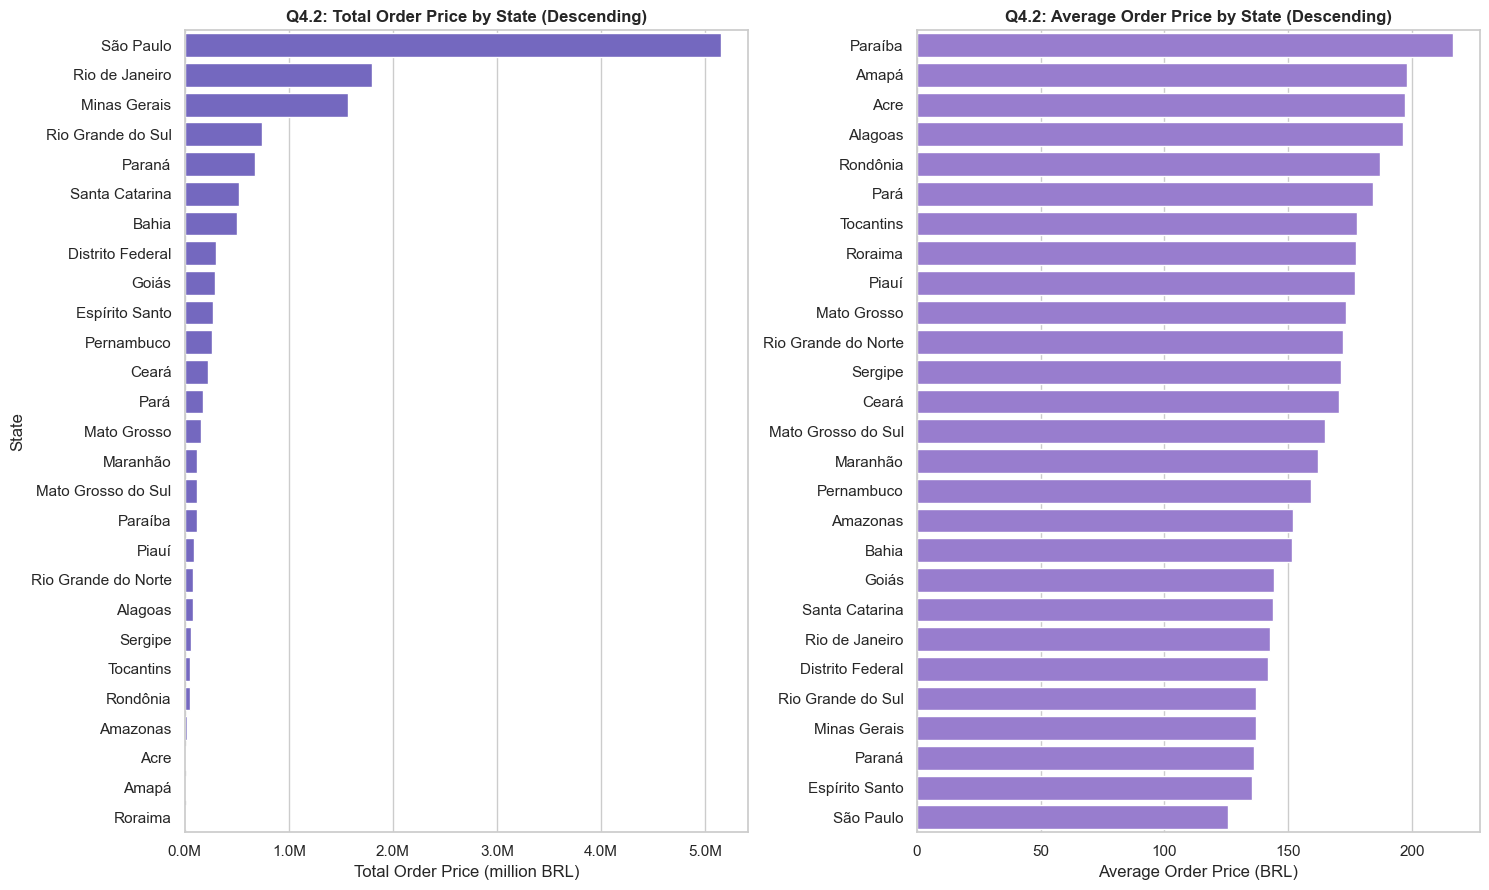

Insights:
  - São Paulo has the highest total order value (38.3% of national GMV) with an average order value of BRL 125.56 (rank 27 of 27).
  - Highest average order value (states with >= 100 orders): Paraíba (BRL 216.65); lowest: São Paulo (BRL 125.56).
  - Average order value ranges from BRL 125.56 to BRL 216.65 across ranked states (73% spread), while total value spans a far wider range because it follows order volume.


In [14]:
QUERY_Q4_2 = """
    SELECT
        ov.customer_state,
        sn.state_name,
        COUNT(*) AS order_count,
        ROUND(SUM(ov.order_price), 2) AS total_order_price,
        ROUND(AVG(ov.order_price), 2) AS avg_order_price,
        ROUND(MEDIAN(ov.order_price), 2) AS median_order_price
    FROM order_values ov
    JOIN state_names sn ON ov.customer_state = sn.state_code
    GROUP BY ov.customer_state, sn.state_name
    ORDER BY total_order_price DESC;
"""

df_4_2 = con.execute(QUERY_Q4_2).df()
display(df_4_2.head(10))
save_df_as_image(df_4_2, f"{OUTPUT_DIR}/table_4_2.jpg", max_rows=len(df_4_2))

fig, axes = plt.subplots(1, 2, figsize=(15, 9))
d_total = df_4_2.sort_values("total_order_price", ascending=False)
d_avg = df_4_2.sort_values("avg_order_price", ascending=False)
sns.barplot(data=d_total, y="state_name", x="total_order_price", color="slateblue", ax=axes[0])
sns.barplot(data=d_avg, y="state_name", x="avg_order_price", color="mediumpurple", ax=axes[1])
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1e6:.1f}M"))
label_axes(axes[0], "Q4.2: Total Order Price by State (Descending)", "Total Order Price (million BRL)", "State")
label_axes(axes[1], "Q4.2: Average Order Price by State (Descending)", "Average Order Price (BRL)", "")
plt.savefig(f"{OUTPUT_DIR}/chart_4_2.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

big = df_4_2.iloc[0]
ranked = df_4_2[df_4_2["order_count"] >= MIN_ORDERS_PER_STATE].sort_values("avg_order_price")
share = big["total_order_price"] / df_4_2["total_order_price"].sum() * 100
print_insights(
    [
        f"{big['state_name']} has the highest total order value ({share:.1f}% of national GMV) with an average order value of BRL {big['avg_order_price']:.2f} (rank {int(df_4_2['avg_order_price'].rank(ascending=False)[0])} of {len(df_4_2)}).",
        f"Highest average order value (states with >= {MIN_ORDERS_PER_STATE} orders): {ranked.iloc[-1]['state_name']} (BRL {ranked.iloc[-1]['avg_order_price']:.2f}); lowest: {ranked.iloc[0]['state_name']} (BRL {ranked.iloc[0]['avg_order_price']:.2f}).",
        f"Average order value ranges from BRL {ranked.iloc[0]['avg_order_price']:.2f} to BRL {ranked.iloc[-1]['avg_order_price']:.2f} across ranked states ({(ranked.iloc[-1]['avg_order_price'] / ranked.iloc[0]['avg_order_price'] - 1) * 100:.0f}% spread), while total value spans a far wider range because it follows order volume.",
    ]
)

## **Q4.3:** What are the total and average freight costs per order per customer state, and is freight lower where order value is higher?

,customer_state,state_name,order_count,total_freight_value,avg_freight_per_order,median_freight_per_order,freight_pct_of_price
0,SP,São Paulo,41021,712453.96,17.37,13.61,13.83
1,MG,Minas Gerais,11457,268790.09,23.46,18.18,17.13
2,PR,Paraná,4962,116834.34,23.55,17.88,17.31
3,DF,Distrito Federal,2114,50284.42,23.79,18.09,16.77
4,RJ,Rio de Janeiro,12654,303113.40,23.95,17.97,16.82
5,ES,Espírito Santo,2014,49399.55,24.53,18.28,18.12
6,SC,Santa Catarina,3590,89182.76,24.84,18.23,17.27
7,RS,Rio Grande do Sul,5395,134277.30,24.89,18.23,18.16
8,GO,Goiás,1990,52503.63,26.38,18.49,18.30
9,MS,Mato Grosso do Sul,708,19121.04,27.01,18.59,16.38


,state_name,value_rank,avg_order_value_rank,avg_freight_per_order,freight_pct_of_price,freight_rank_low_to_high
0,São Paulo,1,27,17.37,13.83,1
1,Rio de Janeiro,2,21,23.95,16.82,5
2,Minas Gerais,3,24,23.46,17.13,2
3,Rio Grande do Sul,4,23,24.89,18.16,8
4,Paraná,5,25,23.55,17.31,3


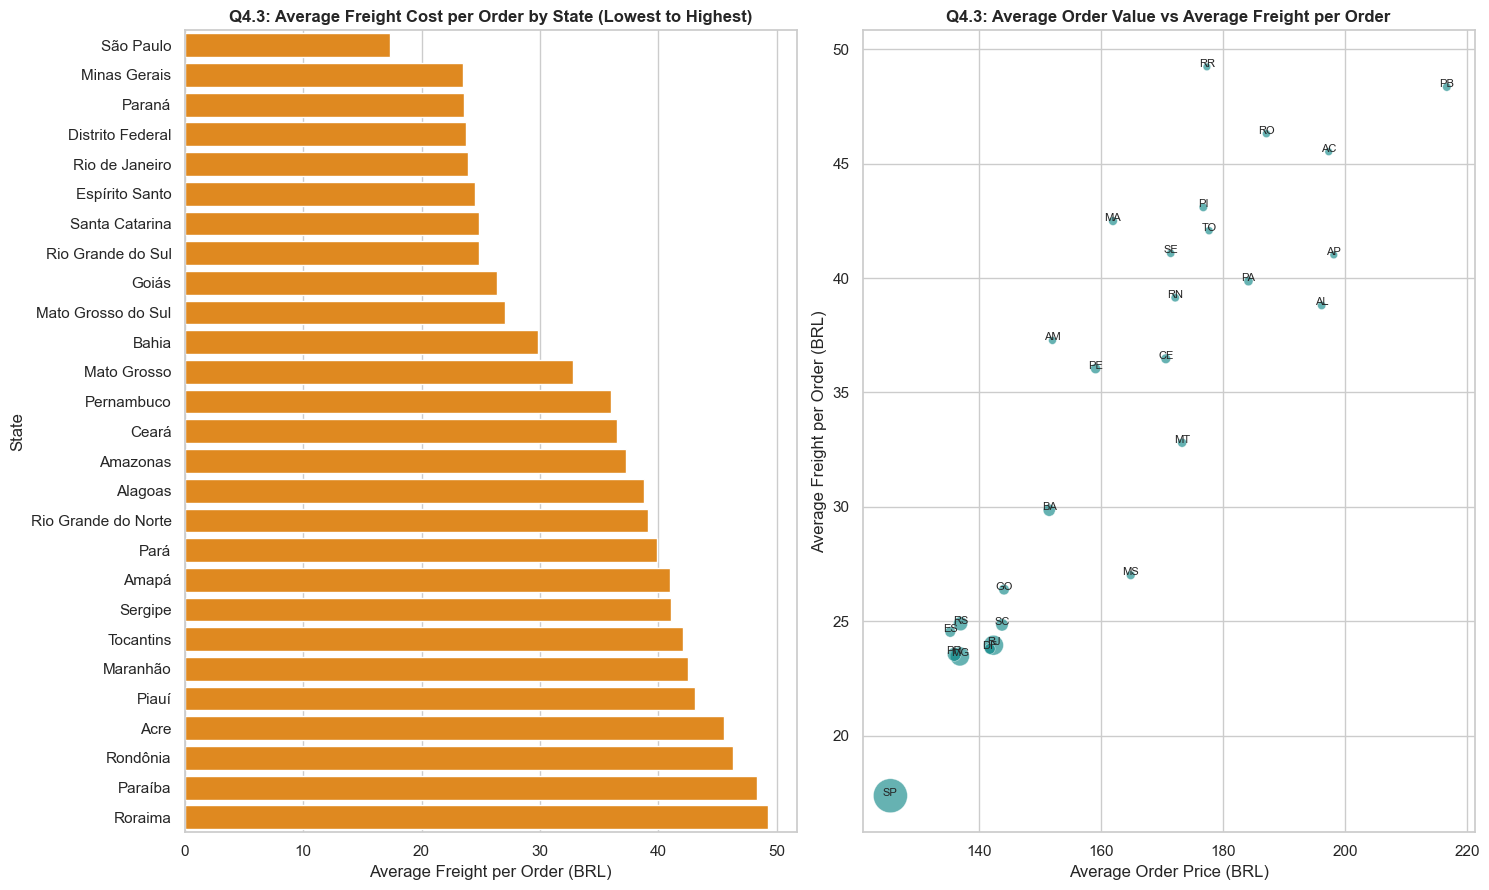

Insights:
  - Lowest average freight per order: São Paulo (BRL 17.37, 13.8% of price). Highest: Roraima (BRL 49.23, 27.8% of price, 43 orders).
  - Top 5 states by total order value and their freight rank: São Paulo (value #1, freight #1 lowest); Rio de Janeiro (value #2, freight #5 lowest); Minas Gerais (value #3, freight #2 lowest); Rio Grande do Sul (value #4, freight #8 lowest); Paraná (value #5, freight #3 lowest).
  - Rank correlation between average order value and average freight across states: +0.88 (near 0 = unrelated).
  - Freight is the shipping charge on the order, not Target's cost; this data cannot show margin. Use freight as a share of price as the affordability measure.


In [15]:
QUERY_Q4_3 = """
    SELECT
        ov.customer_state,
        sn.state_name,
        COUNT(*) AS order_count,
        ROUND(SUM(ov.order_freight), 2) AS total_freight_value,
        ROUND(AVG(ov.order_freight), 2) AS avg_freight_per_order,
        ROUND(MEDIAN(ov.order_freight), 2) AS median_freight_per_order,
        ROUND(100.0 * SUM(ov.order_freight) / SUM(ov.order_price), 2) AS freight_pct_of_price
    FROM order_values ov
    JOIN state_names sn ON ov.customer_state = sn.state_code
    GROUP BY ov.customer_state, sn.state_name
    ORDER BY avg_freight_per_order ASC;
"""

df_4_3 = con.execute(QUERY_Q4_3).df()
display(df_4_3.head(10))
save_df_as_image(df_4_3, f"{OUTPUT_DIR}/table_4_3.jpg", max_rows=len(df_4_3))

# Logistics efficiency check: do high-value states have low freight?
rank_df = df_4_2[["customer_state", "state_name", "total_order_price", "avg_order_price"]].merge(
    df_4_3[["customer_state", "order_count", "avg_freight_per_order", "freight_pct_of_price"]], on="customer_state"
)
rank_df["value_rank"] = rank_df["total_order_price"].rank(ascending=False).astype(int)
rank_df["avg_order_value_rank"] = rank_df["avg_order_price"].rank(ascending=False).astype(int)
rank_df["freight_rank_low_to_high"] = rank_df["avg_freight_per_order"].rank().astype(int)
efficiency = rank_df.sort_values("value_rank").head(5)[
    ["state_name", "value_rank", "avg_order_value_rank", "avg_freight_per_order", "freight_pct_of_price", "freight_rank_low_to_high"]
]
display(efficiency)
save_df_as_image(efficiency, f"{OUTPUT_DIR}/table_4_3b.jpg")

fig, axes = plt.subplots(1, 2, figsize=(15, 9))
sns.barplot(data=df_4_3, y="state_name", x="avg_freight_per_order", color="darkorange", ax=axes[0])
label_axes(axes[0], "Q4.3: Average Freight Cost per Order by State (Lowest to Highest)", "Average Freight per Order (BRL)", "State")
sns.scatterplot(data=rank_df, x="avg_order_price", y="avg_freight_per_order", size="order_count", sizes=(30, 600), legend=False, color="teal", alpha=0.6, ax=axes[1])
for r in rank_df.itertuples():
    axes[1].annotate(r.customer_state, (r.avg_order_price, r.avg_freight_per_order), fontsize=8, ha="center")
label_axes(axes[1], "Q4.3: Average Order Value vs Average Freight per Order", "Average Order Price (BRL)", "Average Freight per Order (BRL)")
plt.savefig(f"{OUTPUT_DIR}/chart_4_3.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

corr = rank_df["avg_order_price"].rank().corr(rank_df["avg_freight_per_order"].rank())
low, high = df_4_3.iloc[0], df_4_3.iloc[-1]
print_insights(
    [
        f"Lowest average freight per order: {low['state_name']} (BRL {low['avg_freight_per_order']:.2f}, {low['freight_pct_of_price']:.1f}% of price). Highest: {high['state_name']} (BRL {high['avg_freight_per_order']:.2f}, {high['freight_pct_of_price']:.1f}% of price, {int(high['order_count'])} orders).",
        "Top 5 states by total order value and their freight rank: "
        + "; ".join(f"{r.state_name} (value #{r.value_rank}, freight #{r.freight_rank_low_to_high} lowest)" for r in efficiency.itertuples()) + ".",
        f"Rank correlation between average order value and average freight across states: {corr:+.2f} (near 0 = unrelated).",
        "Freight is the shipping charge on the order, not Target's cost; this data cannot show margin. Use freight as a share of price as the affordability measure.",
    ]
)

## **Q5.1:** What is the delivery time distribution, the delivery gap, the on-time rate and its effect on review scores?

,order_id,time_to_deliver_days,promised_days,diff_estimated_delivery
0,00e7ee1b050b8499577073aeb2a297a1,8.812500,20,11
1,29150127e6685892b6eab3eec79f59c7,16.661748,25,8
2,b2059ed67ce144a36e2aa97d2c9e9ad2,26.077153,25,-1
3,951670f92359f4fe4a63112aa7306eba,14.998461,28,13
4,6b7d50bd145f6fc7f33cebabd7e49d0f,11.461319,17,6
5,5741ea1f91b5fbab2bd2dc653a5b5099,13.970972,20,6
6,36e694cf4cbc2a4803200c35e84abdc4,1.074491,14,13
7,1093c8304c7a003280dd34598194913d,10.719144,22,11
8,1ebeea841c590e86a14a0d7a48e7d062,8.112650,33,25
9,7433cbcc783205509d66a5260da5b574,5.145382,28,23


,delivered_orders,mean_delivery_days,median_delivery_days,mean_promised_days,mean_gap_days,median_gap_days,on_time_or_early_pct,late_pct,late_over_7_days_pct
0,96203,12.54,10.21,24.28,11.81,12.0,93.21,6.79,2.97


,delivery_status,orders_with_review,avg_review_score,median_review_score,low_score_pct
0,On Time or Early,89182,4.29,5.0,9.21
1,Late,6378,2.27,1.0,62.35


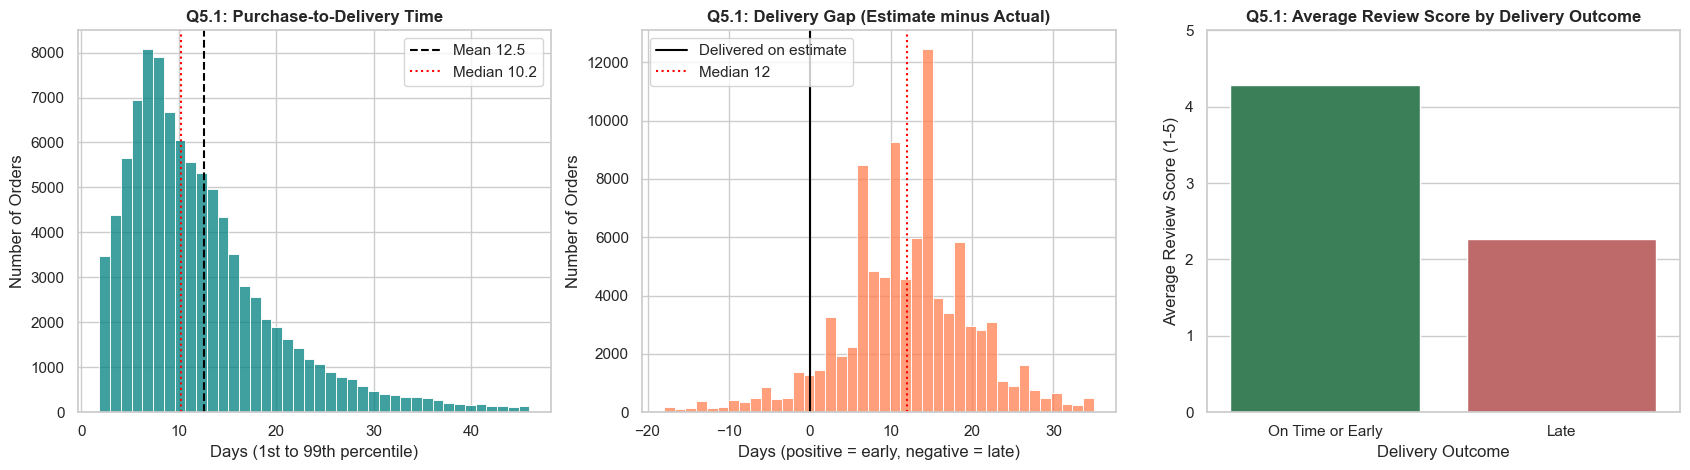

Insights:
  - 96,203 delivered orders: mean delivery time 12.54 days (median 10.21) against a mean promise of 24.28 days.
  - On average orders arrive 11.81 days early (median 12.0), but 6.79% arrive late and 2.97% arrive more than 7 days late. The mean gap hides these late orders.
  - Average review score is 4.29 for on-time/early vs 2.27 for late orders; low scores (1-2) are 9.21% vs 62.35%.


In [16]:
QUERY_Q5_1 = """
    SELECT
        order_id,
        time_to_deliver_days,
        promised_days,
        diff_estimated_delivery
    FROM delivery_metrics;
"""

QUERY_Q5_1_SUMMARY = """
    SELECT
        COUNT(*) AS delivered_orders,
        ROUND(AVG(time_to_deliver_days), 2) AS mean_delivery_days,
        ROUND(MEDIAN(time_to_deliver_days), 2) AS median_delivery_days,
        ROUND(AVG(promised_days), 2) AS mean_promised_days,
        ROUND(AVG(diff_estimated_delivery), 2) AS mean_gap_days,
        ROUND(MEDIAN(diff_estimated_delivery), 2) AS median_gap_days,
        ROUND(100.0 * AVG(CASE WHEN diff_estimated_delivery >= 0 THEN 1 ELSE 0 END), 2) AS on_time_or_early_pct,
        ROUND(100.0 * AVG(CASE WHEN diff_estimated_delivery < 0 THEN 1 ELSE 0 END), 2) AS late_pct,
        ROUND(100.0 * AVG(CASE WHEN diff_estimated_delivery < -7 THEN 1 ELSE 0 END), 2) AS late_over_7_days_pct
    FROM delivery_metrics;
"""

QUERY_Q5_1_REVIEWS = """
    WITH review_scores AS (
        SELECT order_id, AVG(review_score) AS review_score
        FROM order_reviews
        GROUP BY order_id
    )
    SELECT
        CASE WHEN d.diff_estimated_delivery >= 0 THEN 'On Time or Early' ELSE 'Late' END AS delivery_status,
        COUNT(*) AS orders_with_review,
        ROUND(AVG(r.review_score), 2) AS avg_review_score,
        ROUND(MEDIAN(r.review_score), 2) AS median_review_score,
        ROUND(100.0 * AVG(CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END), 2) AS low_score_pct
    FROM delivery_metrics d
    JOIN review_scores r ON d.order_id = r.order_id
    GROUP BY delivery_status
    ORDER BY delivery_status DESC;
"""

df_5_1 = con.execute(QUERY_Q5_1).df()
display(df_5_1.head(10))
save_df_as_image(df_5_1, f"{OUTPUT_DIR}/table_5_1.jpg")

df_5_1s = con.execute(QUERY_Q5_1_SUMMARY).df()
display(df_5_1s)
save_df_as_image(df_5_1s, f"{OUTPUT_DIR}/table_5_1s.jpg")

df_5_1b = con.execute(QUERY_Q5_1_REVIEWS).df()
display(df_5_1b)
save_df_as_image(df_5_1b, f"{OUTPUT_DIR}/table_5_1b.jpg")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
d = df_5_1["time_to_deliver_days"]
lo, hi = d.quantile([0.01, 0.99])
sns.histplot(d[(d >= lo) & (d <= hi)], bins=40, color="teal", ax=axes[0])
axes[0].axvline(d.mean(), color="black", linestyle="--", label=f"Mean {d.mean():.1f}")
axes[0].axvline(d.median(), color="red", linestyle=":", label=f"Median {d.median():.1f}")
axes[0].legend()
label_axes(axes[0], "Q5.1: Purchase-to-Delivery Time", "Days (1st to 99th percentile)", "Number of Orders")
g = df_5_1["diff_estimated_delivery"]
glo, ghi = g.quantile([0.01, 0.99])
sns.histplot(g[(g >= glo) & (g <= ghi)], bins=40, color="coral", ax=axes[1])
axes[1].axvline(0, color="black", linewidth=1.5, label="Delivered on estimate")
axes[1].axvline(g.median(), color="red", linestyle=":", label=f"Median {g.median():.0f}")
axes[1].legend()
label_axes(axes[1], "Q5.1: Delivery Gap (Estimate minus Actual)", "Days (positive = early, negative = late)", "Number of Orders")
sns.barplot(data=df_5_1b, x="delivery_status", y="avg_review_score", hue="delivery_status", legend=False, palette=["seagreen", "indianred"], ax=axes[2])
axes[2].set_ylim(0, 5)
label_axes(axes[2], "Q5.1: Average Review Score by Delivery Outcome", "Delivery Outcome", "Average Review Score (1-5)")
plt.savefig(f"{OUTPUT_DIR}/chart_5_1.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

s = df_5_1s.iloc[0]
rv = df_5_1b.set_index("delivery_status")
lines = [
    f"{int(s['delivered_orders']):,} delivered orders: mean delivery time {s['mean_delivery_days']} days (median {s['median_delivery_days']}) against a mean promise of {s['mean_promised_days']} days.",
    f"On average orders arrive {s['mean_gap_days']} days early (median {s['median_gap_days']}), but {s['late_pct']}% arrive late and {s['late_over_7_days_pct']}% arrive more than 7 days late. The mean gap hides these late orders.",
]
if {"On Time or Early", "Late"} <= set(rv.index):
    lines.append(
        f"Average review score is {rv.loc['On Time or Early', 'avg_review_score']} for on-time/early vs {rv.loc['Late', 'avg_review_score']} for late orders; "
        f"low scores (1-2) are {rv.loc['On Time or Early', 'low_score_pct']}% vs {rv.loc['Late', 'low_score_pct']}%."
    )
print_insights(lines)

## **Q5.2:** Which are the 5 states with the highest and lowest average freight per order?

,customer_state,order_count,avg_freight_per_order,freight_pct_of_price,category,rank_in_group,state_name
0,SP,41021,17.37,13.83,Lowest 5,1,São Paulo
1,MG,11457,23.46,17.13,Lowest 5,2,Minas Gerais
2,PR,4962,23.55,17.31,Lowest 5,3,Paraná
3,DF,2114,23.79,16.77,Lowest 5,4,Distrito Federal
4,RJ,12654,23.95,16.82,Lowest 5,5,Rio de Janeiro
5,PB,530,48.35,22.32,Highest 5,1,Paraíba
6,RO,246,46.31,24.75,Highest 5,2,Rondônia
7,PI,489,43.09,24.37,Highest 5,3,Piauí
8,MA,732,42.49,26.23,Highest 5,4,Maranhão
9,TO,278,42.07,23.67,Highest 5,5,Tocantins


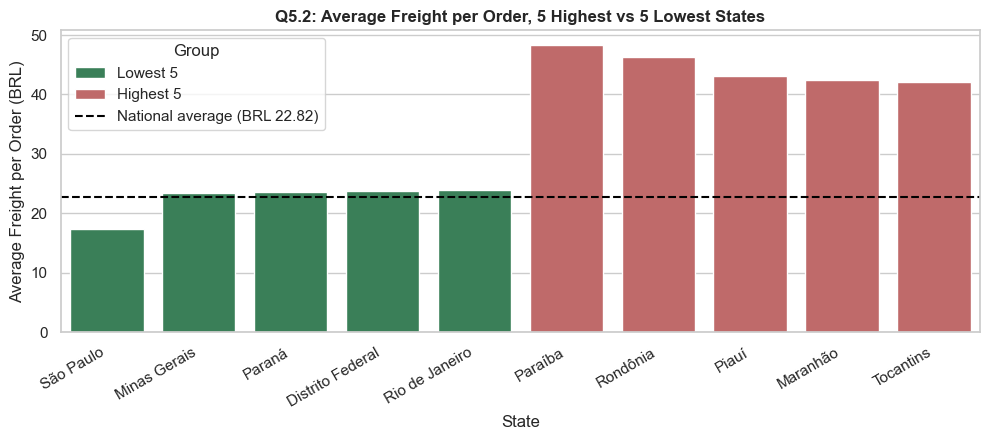

Insights:
  - Highest freight per order: Paraíba (BRL 48.35), Rondônia (BRL 46.31), Piauí (BRL 43.09), Maranhão (BRL 42.49), Tocantins (BRL 42.07).
  - Lowest freight per order: São Paulo (BRL 17.37), Minas Gerais (BRL 23.46), Paraná (BRL 23.55), Distrito Federal (BRL 23.79), Rio de Janeiro (BRL 23.95).
  - National average is BRL 22.82; the most expensive ranked state costs 2.8x the cheapest.
  - States below 100 orders were not ranked: AC, AP, RR.


In [17]:
QUERY_Q5_2 = f"""
    WITH state_freight AS (
        SELECT
            customer_state,
            COUNT(*) AS order_count,
            ROUND(AVG(order_freight), 2) AS avg_freight_per_order,
            ROUND(100.0 * SUM(order_freight) / SUM(order_price), 2) AS freight_pct_of_price
        FROM order_values
        GROUP BY customer_state
        HAVING COUNT(*) >= {MIN_ORDERS_PER_STATE}
    ),
    ranked AS (
        SELECT *,
            ROW_NUMBER() OVER (ORDER BY avg_freight_per_order DESC) AS rank_high,
            ROW_NUMBER() OVER (ORDER BY avg_freight_per_order ASC) AS rank_low
        FROM state_freight
    )
    SELECT customer_state, order_count, avg_freight_per_order, freight_pct_of_price, 'Highest 5' AS category, rank_high AS rank_in_group
    FROM ranked WHERE rank_high <= 5
    UNION ALL
    SELECT customer_state, order_count, avg_freight_per_order, freight_pct_of_price, 'Lowest 5' AS category, rank_low AS rank_in_group
    FROM ranked WHERE rank_low <= 5
    ORDER BY category DESC, rank_in_group ASC;
"""

df_5_2 = con.execute(QUERY_Q5_2).df()
df_5_2["state_name"] = df_5_2["customer_state"].map(STATE_NAMES)
display(df_5_2)
save_df_as_image(df_5_2, f"{OUTPUT_DIR}/table_5_2.jpg")

nat_freight = con.execute("SELECT ROUND(AVG(order_freight), 2) FROM order_values").fetchone()[0]
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=df_5_2, x="state_name", y="avg_freight_per_order", hue="category", dodge=False, palette={"Highest 5": "indianred", "Lowest 5": "seagreen"}, ax=ax)
ax.axhline(nat_freight, color="black", linestyle="--", label=f"National average (BRL {nat_freight})")
ax.legend(title="Group")
plt.xticks(rotation=30, ha="right")
label_axes(ax, "Q5.2: Average Freight per Order, 5 Highest vs 5 Lowest States", "State", "Average Freight per Order (BRL)")
plt.savefig(f"{OUTPUT_DIR}/chart_5_2.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

state_counts = con.execute("SELECT customer_state, COUNT(*) AS order_count FROM order_values GROUP BY 1").df()
small_states = state_counts[state_counts["order_count"] < MIN_ORDERS_PER_STATE]["customer_state"].tolist()
hi5, lo5 = df_5_2[df_5_2["category"] == "Highest 5"], df_5_2[df_5_2["category"] == "Lowest 5"]
print_insights(
    [
        "Highest freight per order: " + ", ".join(f"{r.state_name} (BRL {r.avg_freight_per_order})" for r in hi5.itertuples()) + ".",
        "Lowest freight per order: " + ", ".join(f"{r.state_name} (BRL {r.avg_freight_per_order})" for r in lo5.itertuples()) + ".",
        f"National average is BRL {nat_freight}; the most expensive ranked state costs {hi5['avg_freight_per_order'].max() / lo5['avg_freight_per_order'].min():.1f}x the cheapest.",
        f"States below {MIN_ORDERS_PER_STATE} orders were not ranked: {', '.join(small_states) if small_states else 'none'}.",
    ]
)

## **Q5.3:** Which are the 5 states with the slowest and fastest average delivery times?

,customer_state,order_count,avg_delivery_days,median_delivery_days,category,rank_in_group,state_name
0,AM,145,26.43,25.88,Slowest 5,1,Amazonas
1,AL,396,24.52,22.33,Slowest 5,2,Alagoas
2,PA,942,23.76,21.07,Slowest 5,3,Pará
3,MA,713,21.54,19.18,Slowest 5,4,Maranhão
4,SE,332,21.44,17.93,Slowest 5,5,Sergipe
5,SP,40399,8.74,7.20,Fastest 5,1,São Paulo
6,PR,4903,11.97,10.42,Fastest 5,2,Paraná
7,MG,11319,11.98,10.31,Fastest 5,3,Minas Gerais
8,DF,2074,12.94,11.36,Fastest 5,4,Distrito Federal
9,SC,3537,14.95,13.01,Fastest 5,5,Santa Catarina


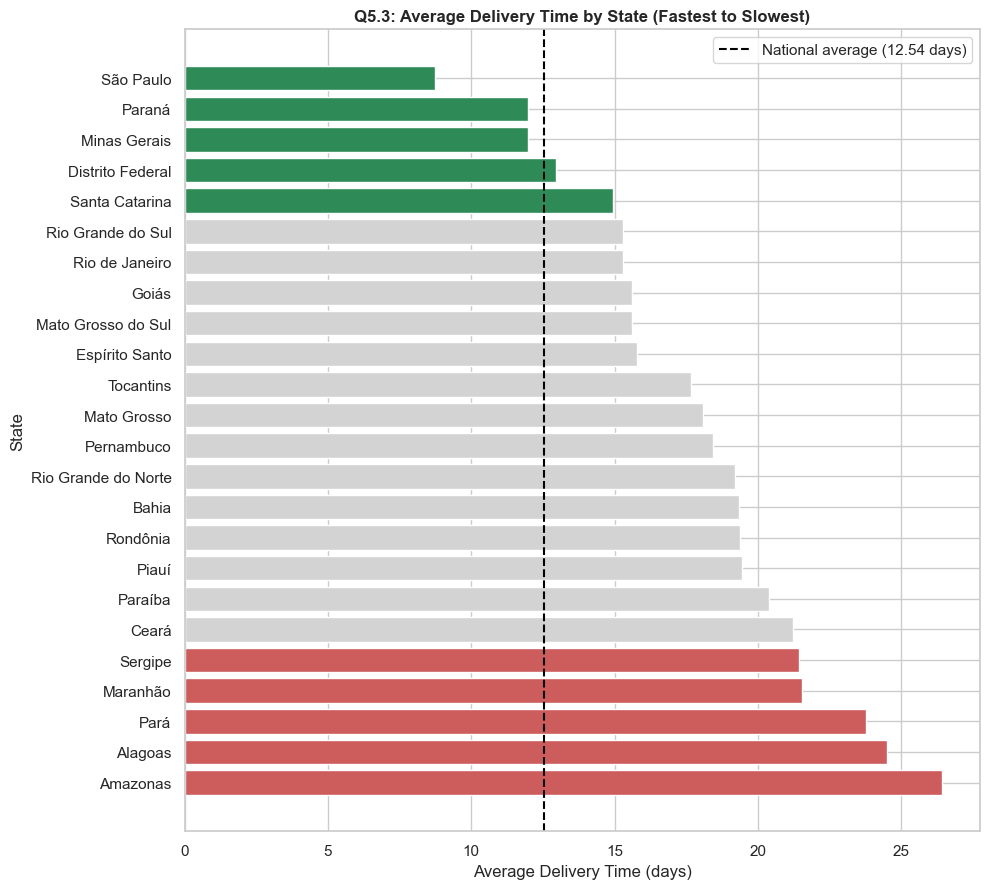

Insights:
  - Slowest: Amazonas (26.43 d, median 25.88), Alagoas (24.52 d, median 22.33), Pará (23.76 d, median 21.07), Maranhão (21.54 d, median 19.18), Sergipe (21.44 d, median 17.93).
  - Fastest: São Paulo (8.74 d, median 7.2), Paraná (11.97 d, median 10.42), Minas Gerais (11.98 d, median 10.31), Distrito Federal (12.94 d, median 11.36), Santa Catarina (14.95 d, median 13.01).
  - National average is 12.54 days; the slowest ranked state is 3.0x the fastest.
  - Green bars = fastest 5, red bars = slowest 5, grey = other states.


In [18]:
QUERY_Q5_3 = f"""
    WITH state_delivery AS (
        SELECT
            customer_state,
            COUNT(*) AS order_count,
            ROUND(AVG(time_to_deliver_days), 2) AS avg_delivery_days,
            ROUND(MEDIAN(time_to_deliver_days), 2) AS median_delivery_days
        FROM delivery_metrics
        GROUP BY customer_state
        HAVING COUNT(*) >= {MIN_ORDERS_PER_STATE}
    ),
    ranked AS (
        SELECT *,
            ROW_NUMBER() OVER (ORDER BY avg_delivery_days DESC) AS rank_slow,
            ROW_NUMBER() OVER (ORDER BY avg_delivery_days ASC) AS rank_fast
        FROM state_delivery
    )
    SELECT customer_state, order_count, avg_delivery_days, median_delivery_days, 'Slowest 5' AS category, rank_slow AS rank_in_group
    FROM ranked WHERE rank_slow <= 5
    UNION ALL
    SELECT customer_state, order_count, avg_delivery_days, median_delivery_days, 'Fastest 5' AS category, rank_fast AS rank_in_group
    FROM ranked WHERE rank_fast <= 5
    ORDER BY category DESC, rank_in_group ASC;
"""

QUERY_Q5_3_ALL = f"""
    SELECT
        customer_state,
        COUNT(*) AS order_count,
        ROUND(AVG(time_to_deliver_days), 2) AS avg_delivery_days
    FROM delivery_metrics
    GROUP BY customer_state
    HAVING COUNT(*) >= {MIN_ORDERS_PER_STATE}
    ORDER BY avg_delivery_days ASC;
"""

df_5_3 = con.execute(QUERY_Q5_3).df()
df_5_3["state_name"] = df_5_3["customer_state"].map(STATE_NAMES)
display(df_5_3)
save_df_as_image(df_5_3, f"{OUTPUT_DIR}/table_5_3.jpg")

df_5_3_all = con.execute(QUERY_Q5_3_ALL).df()
df_5_3_all["state_name"] = df_5_3_all["customer_state"].map(STATE_NAMES)
nat_days = con.execute("SELECT ROUND(AVG(time_to_deliver_days), 2) FROM delivery_metrics").fetchone()[0]
slow_set = set(df_5_3[df_5_3["category"] == "Slowest 5"]["customer_state"])
fast_set = set(df_5_3[df_5_3["category"] == "Fastest 5"]["customer_state"])
bar_colors = ["indianred" if s in slow_set else "seagreen" if s in fast_set else "lightgray" for s in df_5_3_all["customer_state"]]

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(df_5_3_all["state_name"], df_5_3_all["avg_delivery_days"], color=bar_colors)
ax.axvline(nat_days, color="black", linestyle="--", label=f"National average ({nat_days} days)")
ax.invert_yaxis()
ax.legend()
label_axes(ax, "Q5.3: Average Delivery Time by State (Fastest to Slowest)", "Average Delivery Time (days)", "State")
plt.savefig(f"{OUTPUT_DIR}/chart_5_3.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

sl, fa = df_5_3[df_5_3["category"] == "Slowest 5"], df_5_3[df_5_3["category"] == "Fastest 5"]
print_insights(
    [
        "Slowest: " + ", ".join(f"{r.state_name} ({r.avg_delivery_days} d, median {r.median_delivery_days})" for r in sl.itertuples()) + ".",
        "Fastest: " + ", ".join(f"{r.state_name} ({r.avg_delivery_days} d, median {r.median_delivery_days})" for r in fa.itertuples()) + ".",
        f"National average is {nat_days} days; the slowest ranked state is {sl['avg_delivery_days'].max() / fa['avg_delivery_days'].min():.1f}x the fastest.",
        "Green bars = fastest 5, red bars = slowest 5, grey = other states.",
    ]
)

## **Q5.4:** Which 5 states deliver earliest relative to the estimate, and which have the lowest on-time rate?

,customer_state,order_count,avg_days_ahead_of_estimate,median_days_ahead_of_estimate,on_time_or_early_pct,state_name
0,RO,243,20.10,21.0,97.12,Rondônia
1,AM,145,19.57,19.0,97.24,Amazonas
2,MT,885,14.32,15.0,94.01,Mato Grosso
3,PA,942,13.96,16.0,88.75,Pará
4,RS,5327,13.84,15.0,93.90,Rio Grande do Sul


,customer_state,order_count,avg_days_ahead_of_estimate,median_days_ahead_of_estimate,on_time_or_early_pct,state_name
0,AL,396,8.64,10.0,78.54,Alagoas
1,MA,713,9.42,10.0,82.47,Maranhão
2,SE,332,9.86,13.0,84.64,Sergipe
3,PI,475,11.25,14.0,86.11,Piauí
4,CE,1273,10.63,13.0,86.17,Ceará


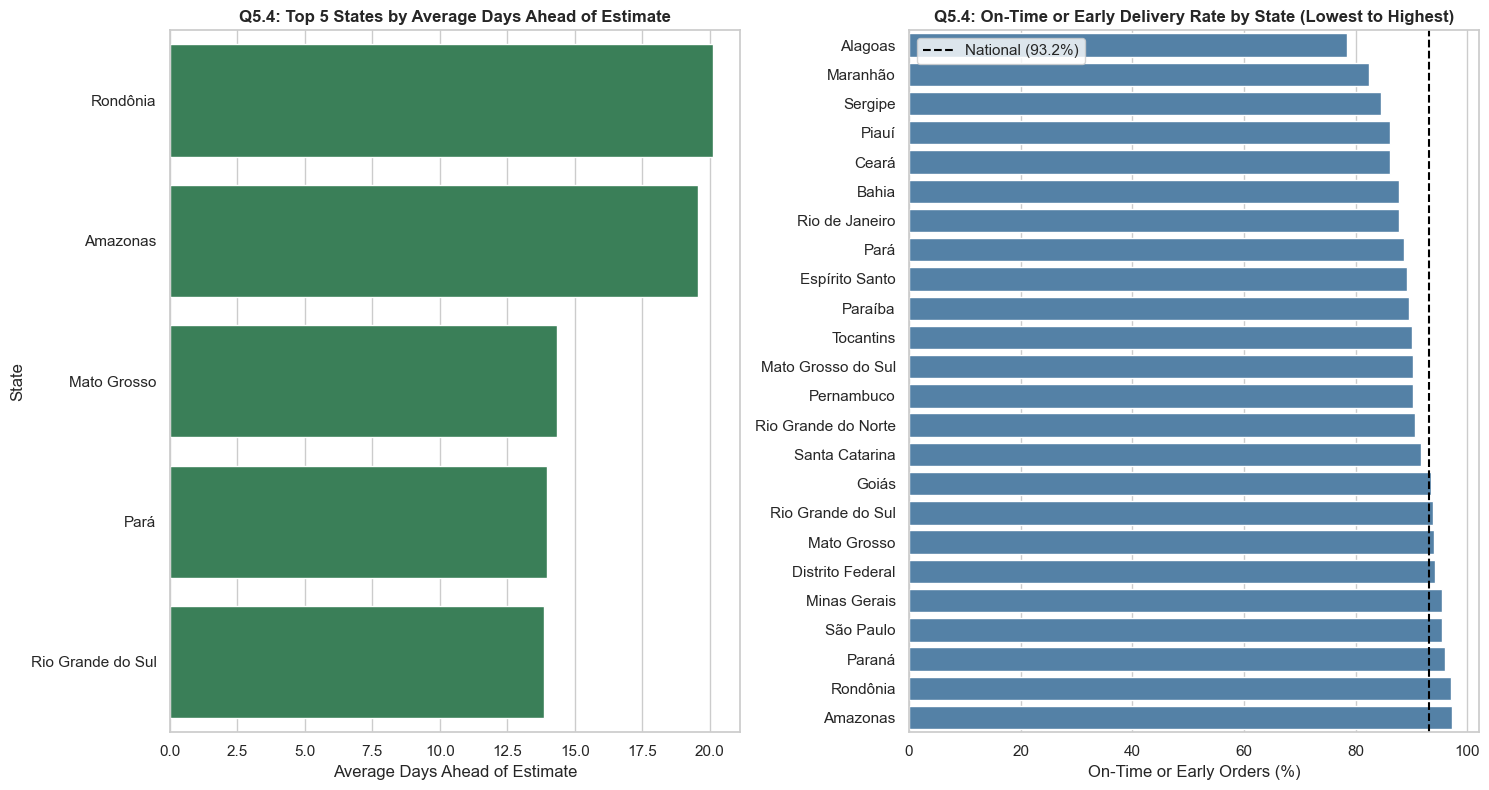

Insights:
  - Earliest vs estimate: Rondônia (20.1 d ahead), Amazonas (19.57 d ahead), Mato Grosso (14.32 d ahead), Pará (13.96 d ahead), Rio Grande do Sul (13.84 d ahead).
  - Lowest on-time rate: Alagoas (78.54%), Maranhão (82.47%), Sergipe (84.64%), Piauí (86.11%), Ceará (86.17%) vs national 93.2%.
  - Large positive gaps show conservative estimates (expectations are exceeded). The on-time rate shows how often the promise was still broken, so both are read together.


In [19]:
QUERY_Q5_4_ALL = f"""
    SELECT
        customer_state,
        COUNT(*) AS order_count,
        ROUND(AVG(diff_estimated_delivery), 2) AS avg_days_ahead_of_estimate,
        ROUND(MEDIAN(diff_estimated_delivery), 2) AS median_days_ahead_of_estimate,
        ROUND(100.0 * AVG(CASE WHEN diff_estimated_delivery >= 0 THEN 1 ELSE 0 END), 2) AS on_time_or_early_pct
    FROM delivery_metrics
    GROUP BY customer_state
    HAVING COUNT(*) >= {MIN_ORDERS_PER_STATE}
    ORDER BY on_time_or_early_pct ASC;
"""

QUERY_Q5_4 = f"""
    SELECT
        customer_state,
        COUNT(*) AS order_count,
        ROUND(AVG(diff_estimated_delivery), 2) AS avg_days_ahead_of_estimate,
        ROUND(MEDIAN(diff_estimated_delivery), 2) AS median_days_ahead_of_estimate,
        ROUND(100.0 * AVG(CASE WHEN diff_estimated_delivery >= 0 THEN 1 ELSE 0 END), 2) AS on_time_or_early_pct
    FROM delivery_metrics
    GROUP BY customer_state
    HAVING COUNT(*) >= {MIN_ORDERS_PER_STATE}
    ORDER BY avg_days_ahead_of_estimate DESC
    LIMIT 5;
"""

df_5_4 = con.execute(QUERY_Q5_4).df()
df_5_4["state_name"] = df_5_4["customer_state"].map(STATE_NAMES)
display(df_5_4)
save_df_as_image(df_5_4, f"{OUTPUT_DIR}/table_5_4.jpg")

df_5_4_all = con.execute(QUERY_Q5_4_ALL).df()
df_5_4_all["state_name"] = df_5_4_all["customer_state"].map(STATE_NAMES)
df_5_4b = df_5_4_all.head(5)
display(df_5_4b)
save_df_as_image(df_5_4b, f"{OUTPUT_DIR}/table_5_4b.jpg")

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
sns.barplot(data=df_5_4, y="state_name", x="avg_days_ahead_of_estimate", color="seagreen", ax=axes[0])
label_axes(axes[0], "Q5.4: Top 5 States by Average Days Ahead of Estimate", "Average Days Ahead of Estimate", "State")
nat_on_time = float(df_5_1s["on_time_or_early_pct"].iloc[0])
sns.barplot(data=df_5_4_all, y="state_name", x="on_time_or_early_pct", color="steelblue", ax=axes[1])
axes[1].axvline(nat_on_time, color="black", linestyle="--", label=f"National ({nat_on_time:.1f}%)")
axes[1].legend()
label_axes(axes[1], "Q5.4: On-Time or Early Delivery Rate by State (Lowest to Highest)", "On-Time or Early Orders (%)", "")
plt.savefig(f"{OUTPUT_DIR}/chart_5_4.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

print_insights(
    [
        "Earliest vs estimate: " + ", ".join(f"{r.state_name} ({r.avg_days_ahead_of_estimate} d ahead)" for r in df_5_4.itertuples()) + ".",
        "Lowest on-time rate: " + ", ".join(f"{r.state_name} ({r.on_time_or_early_pct}%)" for r in df_5_4b.itertuples()) + f" vs national {nat_on_time:.1f}%.",
        "Large positive gaps show conservative estimates (expectations are exceeded). The on-time rate shows how often the promise was still broken, so both are read together.",
    ]
)

## **Q5.5 (supplementary):** Is the freight/delivery advantage explained by seller location or by volume?

,seller_location,order_count,avg_freight_per_order,freight_pct_of_price,avg_delivery_days
0,Seller in Another State,62888,26.98,18.29,15.12
1,Seller in Same State,35017,15.36,12.88,7.92


,seller_state,seller_count,pct_of_sellers,state_name
0,SP,1849,59.74,São Paulo
1,PR,349,11.28,Paraná
2,MG,244,7.88,Minas Gerais
3,SC,190,6.14,Santa Catarina
4,RJ,171,5.53,Rio de Janeiro
5,RS,129,4.17,Rio Grande do Sul
6,GO,40,1.29,Goiás
7,DF,30,0.97,Distrito Federal
8,ES,23,0.74,Espírito Santo
9,BA,19,0.61,Bahia


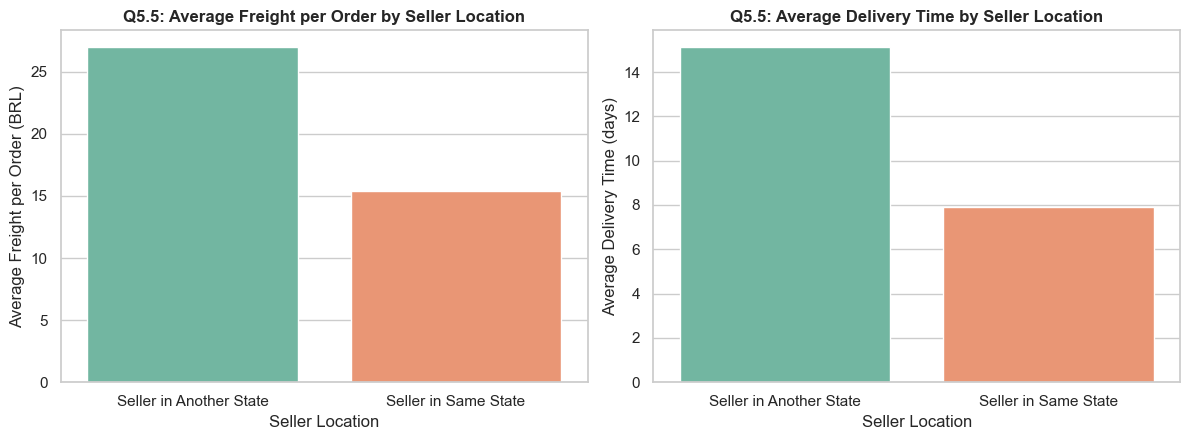

Insights:
  - Same-state orders: BRL 15.36 freight, 7.92 days. Cross-state orders: BRL 26.98 freight, 15.12 days (35.8% of orders are same-state).
  - São Paulo holds 59.7% of all sellers.
  - If same-state orders are much cheaper and faster, the freight/delivery advantage of seller-dense states is mostly proximity, not volume economies of scale. Product weight and mix are not controlled for here.


In [20]:
QUERY_Q5_5 = """
    WITH order_origin AS (
        SELECT
            oi.order_id,
            BOOL_AND(s.seller_state = c.customer_state) AS same_state,
            SUM(oi.price) AS order_price,
            SUM(oi.freight_value) AS order_freight
        FROM order_items oi
        JOIN sellers s ON oi.seller_id = s.seller_id
        JOIN valid_orders o ON oi.order_id = o.order_id
        JOIN customers c ON o.customer_id = c.customer_id
        GROUP BY oi.order_id
    )
    SELECT
        CASE WHEN oo.same_state THEN 'Seller in Same State' ELSE 'Seller in Another State' END AS seller_location,
        COUNT(*) AS order_count,
        ROUND(AVG(oo.order_freight), 2) AS avg_freight_per_order,
        ROUND(100.0 * SUM(oo.order_freight) / SUM(oo.order_price), 2) AS freight_pct_of_price,
        ROUND(AVG(d.time_to_deliver_days), 2) AS avg_delivery_days
    FROM order_origin oo
    LEFT JOIN delivery_metrics d ON oo.order_id = d.order_id
    GROUP BY seller_location
    ORDER BY seller_location ASC;
"""

QUERY_Q5_5_SELLERS = """
    SELECT
        s.seller_state,
        COUNT(*) AS seller_count,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_sellers
    FROM sellers s
    GROUP BY s.seller_state
    ORDER BY seller_count DESC;
"""

df_5_5 = con.execute(QUERY_Q5_5).df()
display(df_5_5)
save_df_as_image(df_5_5, f"{OUTPUT_DIR}/table_5_5.jpg")

df_5_5b = con.execute(QUERY_Q5_5_SELLERS).df()
df_5_5b["state_name"] = df_5_5b["seller_state"].map(STATE_NAMES)
display(df_5_5b.head(10))
save_df_as_image(df_5_5b, f"{OUTPUT_DIR}/table_5_5b.jpg")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=df_5_5, x="seller_location", y="avg_freight_per_order", hue="seller_location", legend=False, palette="Set2", ax=axes[0])
label_axes(axes[0], "Q5.5: Average Freight per Order by Seller Location", "Seller Location", "Average Freight per Order (BRL)")
sns.barplot(data=df_5_5, x="seller_location", y="avg_delivery_days", hue="seller_location", legend=False, palette="Set2", ax=axes[1])
label_axes(axes[1], "Q5.5: Average Delivery Time by Seller Location", "Seller Location", "Average Delivery Time (days)")
plt.savefig(f"{OUTPUT_DIR}/chart_5_5.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

r5 = df_5_5.set_index("seller_location")
lines = []
if {"Seller in Same State", "Seller in Another State"} <= set(r5.index):
    a, b = r5.loc["Seller in Same State"], r5.loc["Seller in Another State"]
    lines.append(
        f"Same-state orders: BRL {a['avg_freight_per_order']} freight, {a['avg_delivery_days']} days. Cross-state orders: BRL {b['avg_freight_per_order']} freight, {b['avg_delivery_days']} days "
        f"({a['order_count'] / (a['order_count'] + b['order_count']) * 100:.1f}% of orders are same-state)."
    )
top_s = df_5_5b.iloc[0]
lines.append(f"{top_s['state_name']} holds {top_s['pct_of_sellers']:.1f}% of all sellers.")
lines.append("If same-state orders are much cheaper and faster, the freight/delivery advantage of seller-dense states is mostly proximity, not volume economies of scale. Product weight and mix are not controlled for here.")
print_insights(lines)

## **Q6.1:** What is the Month-on-Month order count for each payment type?

,year_month,payment_type,total_orders
0,2017-11,credit_card,5867
1,2018-03,credit_card,5674
2,2018-01,credit_card,5511
3,2018-05,credit_card,5475
4,2018-04,credit_card,5441
5,2018-02,credit_card,5235
6,2018-08,credit_card,4963
7,2018-06,credit_card,4796
8,2018-07,credit_card,4738
9,2017-12,credit_card,4363


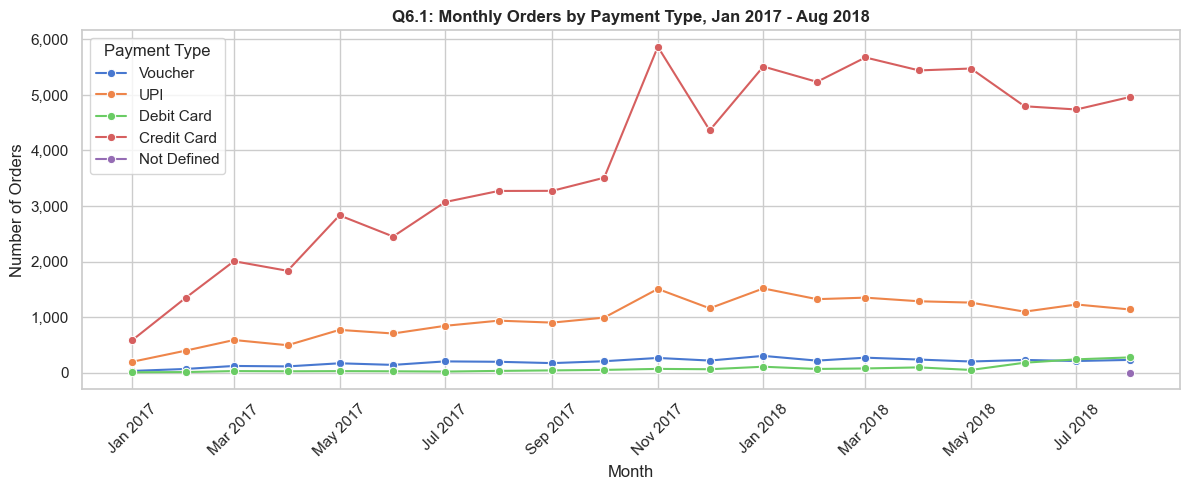

Insights:
  - Order counts by payment type over the window: Credit Card 76,248 (76.9%), UPI 19,721 (19.9%), Voucher 3,836 (3.9%), Debit Card 1,526 (1.5%), Not Defined 2 (0.0%).
  - Shares sum to more than 100% because 99,092 orders can use more than one payment type (e.g., voucher + credit card).
  - The file labels this category `UPI`; the problem statement calls it Boleto. Confirm the mapping before presenting.


In [21]:
QUERY_Q6_1 = """
    SELECT
        STRFTIME(o.order_purchase_timestamp, '%Y-%m') AS year_month,
        p.payment_type,
        COUNT(DISTINCT o.order_id) AS total_orders
    FROM orders_window o
    JOIN payments p ON o.order_id = p.order_id
    GROUP BY year_month, p.payment_type
    ORDER BY total_orders DESC, year_month ASC;
"""

df_6_1 = con.execute(QUERY_Q6_1).df()
display(df_6_1.head(10))
save_df_as_image(df_6_1, f"{OUTPUT_DIR}/table_6_1.jpg")

plot_6_1 = df_6_1.assign(
    month_start=pd.to_datetime(df_6_1["year_month"] + "-01"),
    payment_label=df_6_1["payment_type"].map(pretty),
).sort_values("month_start")
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=plot_6_1, x="month_start", y="total_orders", hue="payment_label", marker="o", ax=ax)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(title="Payment Type")
label_axes(ax, "Q6.1: Monthly Orders by Payment Type, Jan 2017 - Aug 2018", "Month", "Number of Orders")
plt.savefig(f"{OUTPUT_DIR}/chart_6_1.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

tot = df_6_1.groupby("payment_type")["total_orders"].sum().sort_values(ascending=False)
n_orders = int(con.execute("SELECT COUNT(DISTINCT p.order_id) FROM payments p JOIN orders_window o ON p.order_id = o.order_id").fetchone()[0])
print_insights(
    [
        "Order counts by payment type over the window: " + ", ".join(f"{pretty(k)} {int(v):,} ({v / n_orders * 100:.1f}%)" for k, v in tot.items()) + ".",
        f"Shares sum to more than 100% because {n_orders:,} orders can use more than one payment type (e.g., voucher + credit card).",
        "The file labels this category `UPI`; the problem statement calls it Boleto. Confirm the mapping before presenting.",
    ]
)

## **Q6.2:** What is the total number of orders per year for each payment type?

,year,payment_type,total_orders,pct_of_year_orders
0,2017,credit_card,34415,76.31
1,2017,UPI,9508,21.08
2,2017,voucher,1925,4.27
3,2017,debit_card,422,0.94
4,2018,credit_card,41833,77.48
5,2018,UPI,10213,18.92
6,2018,voucher,1911,3.54
7,2018,debit_card,1104,2.04
8,2018,not_defined,2,0.00


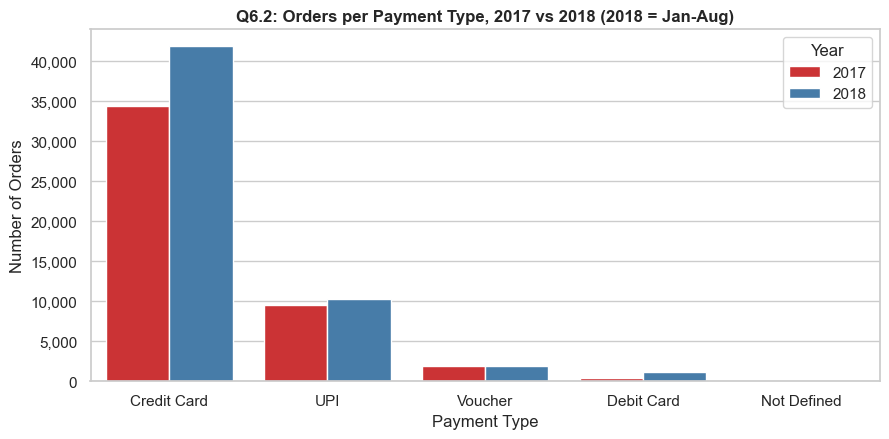

Insights:
  - Share of orders using each payment type (2017 / 2018): UPI 21.1% / 18.9%; Credit Card 76.3% / 77.5%; Debit Card 0.9% / 2.0%; Not Defined nan% / 0.0%; Voucher 4.3% / 3.5%.
  - 2018 covers Jan-Aug only, so compare payment shares (%) rather than raw counts across years.


In [22]:
QUERY_Q6_2 = """
    WITH order_payments AS (
        SELECT
            EXTRACT(YEAR FROM o.order_purchase_timestamp) AS year,
            o.order_id,
            p.payment_type
        FROM orders_window o
        JOIN payments p ON o.order_id = p.order_id
    ),
    year_totals AS (
        SELECT year, COUNT(DISTINCT order_id) AS orders_in_year
        FROM order_payments
        GROUP BY year
    )
    SELECT
        op.year,
        op.payment_type,
        COUNT(DISTINCT op.order_id) AS total_orders,
        ROUND(100.0 * COUNT(DISTINCT op.order_id) / MAX(yt.orders_in_year), 2) AS pct_of_year_orders
    FROM order_payments op
    JOIN year_totals yt ON op.year = yt.year
    GROUP BY op.year, op.payment_type
    ORDER BY op.year ASC, total_orders DESC;
"""

df_6_2 = con.execute(QUERY_Q6_2).df()
display(df_6_2)
save_df_as_image(df_6_2, f"{OUTPUT_DIR}/table_6_2.jpg", max_rows=len(df_6_2))

plot_6_2 = df_6_2.assign(payment_label=df_6_2["payment_type"].map(pretty))
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=plot_6_2, x="payment_label", y="total_orders", hue="year", palette="Set1", ax=ax)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(title="Year")
label_axes(ax, "Q6.2: Orders per Payment Type, 2017 vs 2018 (2018 = Jan-Aug)", "Payment Type", "Number of Orders")
plt.savefig(f"{OUTPUT_DIR}/chart_6_2.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

mix = df_6_2.pivot(index="payment_type", columns="year", values="pct_of_year_orders")
print_insights(
    [
        "Share of orders using each payment type (2017 / 2018): " + "; ".join(f"{pretty(k)} {r.get(2017, float('nan')):.1f}% / {r.get(2018, float('nan')):.1f}%" for k, r in mix.iterrows()) + ".",
        "2018 covers Jan-Aug only, so compare payment shares (%) rather than raw counts across years.",
    ]
)

## **Q6.3:** How are orders distributed by number of payment installments?

,payment_installments,total_orders,pct_of_orders
0,0,2,0.00
1,1,48120,48.56
2,2,12332,12.45
3,3,10385,10.48
4,4,7044,7.11
5,5,5207,5.25
6,6,3890,3.93
7,7,1609,1.62
8,8,4248,4.29
9,9,641,0.65


,payment_type,total_orders,avg_installments,median_installments,pct_multi_installment
0,credit_card,76248,3.5,3.0,66.81
1,UPI,19721,1.0,1.0,0.00
2,voucher,3836,1.0,1.0,0.00
3,debit_card,1526,1.0,1.0,0.00
4,not_defined,2,1.0,1.0,0.00


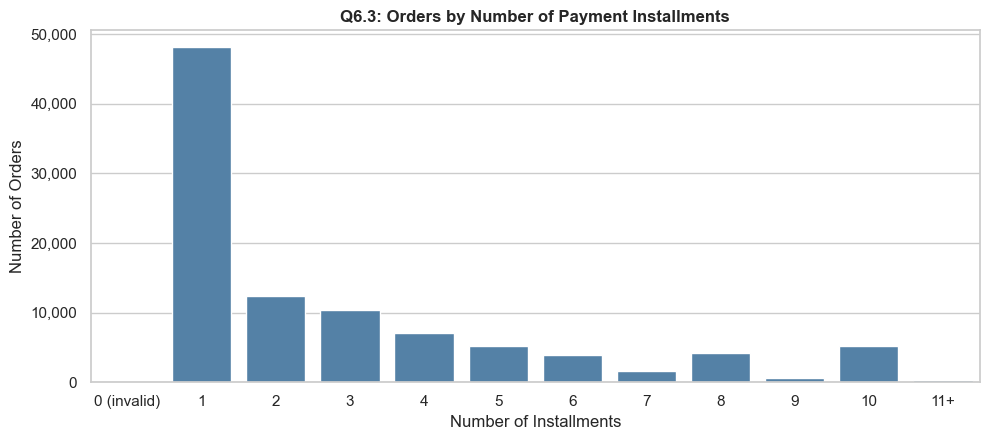

Insights:
  - Single-payment orders are 48.6% of orders; 51.4% use installments.
  - 185 orders use more than 12 installments and 2 orders have 0 installments (invalid); both are kept in the table rather than dropped.
  - Credit card: mean 3.5 installments (median 3.0); 66.81% of credit-card payments are multi-installment.


In [23]:
QUERY_Q6_3 = """
    WITH order_installments AS (
        SELECT p.order_id, MAX(p.payment_installments) AS installments
        FROM payments p
        JOIN orders_window o ON p.order_id = o.order_id
        GROUP BY p.order_id
    )
    SELECT
        installments AS payment_installments,
        COUNT(*) AS total_orders,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_orders
    FROM order_installments
    GROUP BY installments
    ORDER BY installments ASC;
"""

QUERY_Q6_3_BY_TYPE = """
    SELECT
        p.payment_type,
        COUNT(DISTINCT p.order_id) AS total_orders,
        ROUND(AVG(p.payment_installments), 2) AS avg_installments,
        ROUND(MEDIAN(p.payment_installments), 2) AS median_installments,
        ROUND(100.0 * AVG(CASE WHEN p.payment_installments > 1 THEN 1 ELSE 0 END), 2) AS pct_multi_installment
    FROM payments p
    JOIN orders_window o ON p.order_id = o.order_id
    GROUP BY p.payment_type
    ORDER BY total_orders DESC;
"""

df_6_3 = con.execute(QUERY_Q6_3).df()
display(df_6_3.head(10))
save_df_as_image(df_6_3, f"{OUTPUT_DIR}/table_6_3.jpg", max_rows=len(df_6_3))

df_6_3b = con.execute(QUERY_Q6_3_BY_TYPE).df()
display(df_6_3b)
save_df_as_image(df_6_3b, f"{OUTPUT_DIR}/table_6_3b.jpg")

plot_6_3 = df_6_3.copy()
plot_6_3["installment_group"] = plot_6_3["payment_installments"].apply(lambda n: "0 (invalid)" if n == 0 else str(int(n)) if n <= 10 else "11+")
order_labels = ["0 (invalid)"] + [str(i) for i in range(1, 11)] + ["11+"]
grouped = plot_6_3.groupby("installment_group", as_index=False)["total_orders"].sum()
grouped["installment_group"] = pd.Categorical(grouped["installment_group"], categories=order_labels, ordered=True)
grouped = grouped.sort_values("installment_group")
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=grouped, x="installment_group", y="total_orders", color="steelblue", ax=ax)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
label_axes(ax, "Q6.3: Orders by Number of Payment Installments", "Number of Installments", "Number of Orders")
plt.savefig(f"{OUTPUT_DIR}/chart_6_3.jpg", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

one = df_6_3.loc[df_6_3["payment_installments"] == 1, "pct_of_orders"].sum()
over12 = df_6_3.loc[df_6_3["payment_installments"] > 12, "total_orders"].sum()
zero = df_6_3.loc[df_6_3["payment_installments"] == 0, "total_orders"].sum()
cc = df_6_3b[df_6_3b["payment_type"] == "credit_card"]
lines = [
    f"Single-payment orders are {one:.1f}% of orders; {100 - one:.1f}% use installments.",
    f"{int(over12):,} orders use more than 12 installments and {int(zero):,} orders have 0 installments (invalid); both are kept in the table rather than dropped.",
]
if len(cc):
    lines.append(f"Credit card: mean {cc['avg_installments'].iloc[0]} installments (median {cc['median_installments'].iloc[0]}); {cc['pct_multi_installment'].iloc[0]}% of credit-card payments are multi-installment.")
print_insights(lines)

## **Q7:** Key Metrics Summary (Jan-Aug 2017 vs Jan-Aug 2018)

In [24]:
QUERY_Q7 = """
    WITH jan_aug AS (
        SELECT * FROM orders_window
        WHERE EXTRACT(MONTH FROM order_purchase_timestamp) BETWEEN 1 AND 8
    ),
    review_scores AS (
        SELECT order_id, AVG(review_score) AS review_score FROM order_reviews GROUP BY order_id
    ),
    item_totals AS (
        SELECT order_id, SUM(price) AS price, SUM(freight_value) AS freight FROM order_items GROUP BY order_id
    )
    SELECT
        EXTRACT(YEAR FROM o.order_purchase_timestamp) AS year,
        COUNT(*) AS orders_placed,
        ROUND(100.0 * AVG(CASE WHEN o.order_status IN ('canceled', 'unavailable') THEN 1 ELSE 0 END), 2) AS canceled_or_unavailable_pct,
        ROUND(SUM(v.price) FILTER (WHERE o.order_status NOT IN ('canceled', 'unavailable')), 2) AS gmv_brl,
        ROUND(AVG(v.price) FILTER (WHERE o.order_status NOT IN ('canceled', 'unavailable')), 2) AS avg_order_value_brl,
        ROUND(AVG(v.freight) FILTER (WHERE o.order_status NOT IN ('canceled', 'unavailable')), 2) AS avg_freight_per_order_brl,
        ROUND(100.0 * SUM(v.freight) FILTER (WHERE o.order_status NOT IN ('canceled', 'unavailable'))
              / SUM(v.price) FILTER (WHERE o.order_status NOT IN ('canceled', 'unavailable')), 2) AS freight_pct_of_price,
        ROUND(AVG(d.time_to_deliver_days), 2) AS avg_delivery_days,
        ROUND(MEDIAN(d.time_to_deliver_days), 2) AS median_delivery_days,
        ROUND(100.0 * AVG(CASE WHEN d.diff_estimated_delivery >= 0 THEN 1 ELSE 0 END) FILTER (WHERE d.order_id IS NOT NULL), 2) AS on_time_or_early_pct,
        ROUND(AVG(r.review_score), 2) AS avg_review_score
    FROM jan_aug o
    LEFT JOIN item_totals v ON o.order_id = v.order_id
    LEFT JOIN delivery_metrics d ON o.order_id = d.order_id
    LEFT JOIN review_scores r ON o.order_id = r.order_id
    GROUP BY year
    ORDER BY year ASC;
"""

QUERY_Q7_RETENTION = """
    WITH customer_orders AS (
        SELECT
            c.customer_unique_id,
            COUNT(DISTINCT o.order_id) AS orders,
            SUM(ov.order_price) AS spend
        FROM valid_orders o
        JOIN customers c ON o.customer_id = c.customer_id
        JOIN order_values ov ON o.order_id = ov.order_id
        GROUP BY c.customer_unique_id
    )
    SELECT
        COUNT(*) AS unique_customers,
        ROUND(100.0 * AVG(CASE WHEN orders > 1 THEN 1 ELSE 0 END), 2) AS repeat_customer_pct,
        ROUND(AVG(orders), 3) AS orders_per_customer,
        ROUND(AVG(spend), 2) AS revenue_per_customer_brl
    FROM customer_orders;
"""

df_7 = con.execute(QUERY_Q7).df()
kpi = df_7.set_index("year").T
kpi.columns = [f"Jan-Aug {int(c)}" for c in kpi.columns]
kpi["Change (%)"] = ((kpi.iloc[:, 1] / kpi.iloc[:, 0] - 1) * 100).round(2)
kpi.index = [pretty(i) for i in kpi.index]
kpi = kpi.reset_index().rename(columns={"index": "Metric"})
display(kpi)
save_df_as_image(kpi, f"{OUTPUT_DIR}/table_7.jpg", max_rows=len(kpi))

df_7r = con.execute(QUERY_Q7_RETENTION).df()
display(df_7r)
save_df_as_image(df_7r, f"{OUTPUT_DIR}/table_7r.jpg")

print_insights(
    [
        f"{df_7r['repeat_customer_pct'].iloc[0]}% of {int(df_7r['unique_customers'].iloc[0]):,} unique customers ordered more than once in the window (by `customer_unique_id`).",
        f"Revenue per customer of BRL {df_7r['revenue_per_customer_brl'].iloc[0]} is a window-only proxy, not lifetime value.",
        "Percent-change rows for rates (cancel %, on-time %, freight %) are relative changes; read the absolute values alongside them.",
    ]
)

,Metric,Jan-Aug 2017,Jan-Aug 2018,Change (%)
0,Orders Placed,22968.00,53991.00,135.07
1,Canceled Or Unavailable Pct,1.77,0.85,-51.98
2,Gmv Brl,3080850.81,7341037.41,138.28
3,Avg Order Value Brl,136.55,137.14,0.43
4,Avg Freight Per Order Brl,21.90,23.39,6.80
5,Freight Pct Of Price,16.04,17.06,6.36
6,Avg Delivery Days,12.18,12.14,-0.33
7,Median Delivery Days,10.44,9.48,-9.20
8,On Time Or Early Pct,96.50,92.27,-4.38
9,Avg Review Score,4.14,4.09,-1.21


,unique_customers,repeat_customer_pct,orders_per_customer,revenue_per_customer_brl
0,94703,3.03,1.034,142.02


Insights:
  - 3.03% of 94,703 unique customers ordered more than once in the window (by `customer_unique_id`).
  - Revenue per customer of BRL 142.02 is a window-only proxy, not lifetime value.
  - Percent-change rows for rates (cancel %, on-time %, freight %) are relative changes; read the absolute values alongside them.


## Recommendations

Each recommendation below is printed from the metrics computed above, so numbers always match the data. Where the dataset cannot prove an effect, the item is framed as a test.

In [25]:
recs = []

# 1. Delivery reliability (primary lever: late-delivery states)
late_states = df_5_4b[df_5_4b["on_time_or_early_pct"] < nat_on_time]
if len(late_states):
    recs.append(
        "1. Fix delivery reliability where it fails: "
        + ", ".join(f"{r.state_name} ({r.on_time_or_early_pct}%)" for r in late_states.itertuples())
        + f" have the lowest on-time rates (national {nat_on_time:.1f}%). Review carrier SLAs and routing for these states first."
    )

# 2. Delivery estimates: evidence-gated, not a default change
rv = df_5_1b.set_index("delivery_status")
if {"On Time or Early", "Late"} <= set(rv.index):
    gap = rv.loc["On Time or Early", "avg_review_score"] - rv.loc["Late", "avg_review_score"]
    recs.append(
        f"2. Do not change the estimate algorithm without a trigger: this dataset has no conversion data, so it cannot show whether long estimates cost sales. "
        f"Change it only if a competitor promises faster and delivers on it. Meanwhile, reduce the {df_5_1s['late_pct'].iloc[0]}% late rate"
        + (f": late orders score {gap:.2f} points lower on average." if gap > 0 else " (late orders do not score lower here, so the review impact is weak).")
    )

# 3. Freight and seller location
r5 = df_5_5.set_index("seller_location")
if {"Seller in Same State", "Seller in Another State"} <= set(r5.index):
    same, cross = r5.loc["Seller in Same State"], r5.loc["Seller in Another State"]
    if same["avg_freight_per_order"] < cross["avg_freight_per_order"]:
        recs.append(
            f"3. Freight is lower and delivery faster when the seller is in the buyer's state (BRL {same['avg_freight_per_order']} vs {cross['avg_freight_per_order']}; {same['avg_delivery_days']} vs {cross['avg_delivery_days']} days). "
            f"Recruit sellers or stage inventory in high-freight regions ({', '.join(hi5['state_name'].head(3))}) rather than assuming volume alone lowers cost."
        )

# 4. Logistics efficiency of high-value states
inefficient = efficiency[efficiency["freight_rank_low_to_high"] > len(df_4_3) / 2]
if len(inefficient):
    recs.append(
        "4. Among the top-5 states by order value, review freight in: "
        + ", ".join(f"{r.state_name} (freight rank #{r.freight_rank_low_to_high} of {len(df_4_3)}, {r.freight_pct_of_price}% of price)" for r in inefficient.itertuples())
        + "."
    )
else:
    recs.append("4. All top-5 states by order value sit in the lower half of freight cost; focus freight work on remote, high-freight states instead.")

# 5. Payments
cc_share = df_6_1.groupby("payment_type")["total_orders"].sum().get("credit_card", 0) / n_orders * 100
recs.append(
    f"5. Credit card is used in {cc_share:.1f}% of orders and {one:.1f}% of orders are single-payment. Run an A/B test of cashback or vouchers on a small installment-heavy segment, and check cost against margin data first (not in this dataset)."
)

# 6. Timing
recs.append(
    f"6. Schedule promotions and support staffing for the {df_2_3b['time_of_day'].iloc[0]} window and {df_2_4.loc[df_2_4['order_count'].idxmax(), 'day_of_week']}s, the busiest slots in the data."
)

# 7. Retention
recs.append(
    f"7. Only {df_7r['repeat_customer_pct'].iloc[0]}% of customers ordered more than once. Treat repeat purchase as the main growth lever to study (needs cohort and marketing data)."
)

# 8. Data gaps
recs.append(
    "8. Capture cost of goods, shipping cost paid by Target, sessions/cart data and returns. Without them margin, conversion and true LTV cannot be answered."
)

for r in recs:
    print(r + "\n")

1. Fix delivery reliability where it fails: Alagoas (78.54%), Maranhão (82.47%), Sergipe (84.64%), Piauí (86.11%), Ceará (86.17%) have the lowest on-time rates (national 93.2%). Review carrier SLAs and routing for these states first.

2. Do not change the estimate algorithm without a trigger: this dataset has no conversion data, so it cannot show whether long estimates cost sales. Change it only if a competitor promises faster and delivers on it. Meanwhile, reduce the 6.79% late rate: late orders score 2.02 points lower on average.

3. Freight is lower and delivery faster when the seller is in the buyer's state (BRL 15.36 vs 26.98; 7.92 vs 15.12 days). Recruit sellers or stage inventory in high-freight regions (Paraíba, Rondônia, Piauí) rather than assuming volume alone lowers cost.

4. All top-5 states by order value sit in the lower half of freight cost; focus freight work on remote, high-freight states instead.

5. Credit card is used in 76.9% of orders and 48.6% of orders are singl

### Data notes and limitations

* Orders from 2016 and Sep-Oct 2018 are excluded (partial coverage). Only two calendar years remain, so no yearly trend is claimed.
* `freight_value` is the shipping charge on an item and not Target's logistics cost. No cost, margin or seller-payout data exists, so profitability is not assessed.
* State rankings require at least `MIN_ORDERS_PER_STATE` orders.
* Delivery metrics cover delivered orders only; delivery gap uses calendar dates, delivery time uses 24-hour periods.
* Payment category `UPI` replaces `boleto` in this file.
* State-level freight and delivery differences are not controlled for product weight or category mix.